<a href="https://colab.research.google.com/github/rohithrajulapati/healthcare-fraud-xai/blob/main/01_data_acquisition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Explainable AI for Detecting Fraud, Waste, and Abuse in U.S. Healthcare Claims

## Notebook 01: Data Acquisition

### Objectives
1. Configure the Python environment.
2. Connect to the official CMS data API.
3. Retrieve a sample of Medicare provider and service records.
4. Inspect the dataset structure.
5. Prepare for historical data acquisition.

In [1]:
!pip install -q pandas numpy requests pyarrow tqdm

In [2]:
import sys
import pandas as pd
import numpy as np
import requests
import pyarrow

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Requests version:", requests.__version__)
print("PyArrow version:", pyarrow.__version__)

print("\nEnvironment setup completed successfully!")


Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.4.6
Requests version: 2.32.4
PyArrow version: 23.0.1

Environment setup completed successfully!


In [3]:
import requests
import pandas as pd

CMS_DATASET_ID = "335e5f35-eca6-482d-87b3-f99883e213e3"

CMS_API_URL = (
    f"https://data.cms.gov/data-api/v1/dataset/"
    f"{CMS_DATASET_ID}/data"
)

params = {
    "size": 10,
    "offset": 0
}

response = requests.get(
    CMS_API_URL,
    params=params,
    timeout=60
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

records = response.json()

print("Records retrieved:", len(records))

cms_sample = pd.DataFrame(records)

print("\nDataset dimensions:", cms_sample.shape)

print("\nColumn names:")
print(cms_sample.columns.tolist())

print("\nFirst five records:")
display(cms_sample.head())

HTTP Status: 200
Records retrieved: 10

Dataset dimensions: (10, 28)

Column names:
['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']

First five records:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36,36,284.37888889,79.063888889,60.828888889,62.376388889
1,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150,150,352.17633333,126.3408,95.6756,96.007133333
2,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63,63,783.99730159,170.36,134.30047619,131.99936508
3,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16,16,122.125,47.8325,33.350625,33.70625
4,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70,70,583.60685714,81.428571429,62.728714286,58.486857143


In [5]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

SAMPLE_DIR = PROJECT_DIR / "data" / "external"

SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

sample_path = SAMPLE_DIR / "cms_2024_sample.csv"

cms_sample.to_csv(sample_path, index=False)

print("Sample saved successfully!")
print("Location:", sample_path)

Sample saved successfully!
Location: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_2024_sample.csv


## Step 3: Discover Historical CMS Releases

We will identify the official annual CMS releases from 2018 through 2024.

The discovery process will retrieve the dataset metadata, API identifiers,
and available CSV download URLs.

In [8]:

import requests
import pandas as pd
import re

CMS_CATALOG_URL = "https://data.cms.gov/data.json"

print("Connecting to the official CMS catalog...")

response = requests.get(
    CMS_CATALOG_URL,
    timeout=120
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

catalog = response.json()

# Handle common JSON-LD catalog structures
datasets = catalog.get("dataset", catalog.get("@graph", []))

if isinstance(datasets, dict):
    datasets = [datasets]

TARGET = "medicare physician & other practitioners - by provider and service"

release_records = []

for dataset in datasets:

    title = dataset.get("title", "")

    if TARGET not in title.lower():
        continue

    distributions = dataset.get("distribution", [])

    if isinstance(distributions, dict):
        distributions = [distributions]

    for resource in distributions:

        api_url = resource.get("accessURL", "")
        csv_url = resource.get("downloadURL", "")

        if not api_url:
            continue

        # Extract the year from the release title
        year_match = re.search(r"20\d{2}", title)

        if not year_match:
            continue

        year = int(year_match.group())

        if year < 2018 or year > 2024:
            continue

        release_records.append({
            "year": year,
            "dataset_title": title,
            "api_url": api_url,
            "csv_url": csv_url
        })

releases_df = pd.DataFrame(release_records)

if releases_df.empty:
    print("No annual releases found in the initial catalog structure.")
    print("Catalog keys:", list(catalog.keys()))
    print("Dataset records:", len(datasets))
else:
    releases_df = (
        releases_df
        .drop_duplicates(subset=["year", "api_url"])
        .sort_values("year")
        .reset_index(drop=True)
    )

    print("\nAnnual releases discovered:")
    display(releases_df)
    print("\nYears found:", sorted(releases_df["year"].unique()))
    print("Total release records:", len(releases_df))


Connecting to the official CMS catalog...
HTTP Status: 200

Annual releases discovered:


,year,dataset_title,api_url,csv_url
0,2018,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/fb6d9...,
1,2019,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/867b8...,
2,2020,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/c957b...,
3,2021,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/31dc2...,
4,2022,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/e6509...,
5,2023,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/0e9f2...,
6,2024,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/92396...,
7,2024,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/335e5...,



Years found: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Total release records: 8


In [9]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

METADATA_DIR = PROJECT_DIR / "data" / "external"

METADATA_DIR.mkdir(parents=True, exist_ok=True)

metadata_path = METADATA_DIR / "cms_historical_releases.csv"

releases_df.to_csv(metadata_path, index=False)

print("Release metadata saved:")
print(metadata_path)

Release metadata saved:
/content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_historical_releases.csv


## Verified CMS Annual Release Manifest

This section records verified CMS API identifiers.
Only releases with confirmed metadata will be used for downloading.

In [10]:

import pandas as pd
import requests

CMS_RELEASES = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3",
}

def validate_release(year, dataset_id):
    url = (
        f"https://data.cms.gov/data-api/v1/dataset/"
        f"{dataset_id}/data"
    )

    try:
        response = requests.get(
            url,
            params={"size": 2, "offset": 0},
            timeout=60
        )

        response.raise_for_status()
        records = response.json()

        return {
            "year": year,
            "dataset_id": dataset_id,
            "http_status": response.status_code,
            "sample_rows": len(records),
            "status": "VALID" if records else "EMPTY"
        }

    except Exception as error:
        return {
            "year": year,
            "dataset_id": dataset_id,
            "http_status": None,
            "sample_rows": 0,
            "status": f"ERROR: {error}"
        }

validation_results = []

for year, dataset_id in CMS_RELEASES.items():
    print(f"Checking CMS release: {year}")
    validation_results.append(
        validate_release(year, dataset_id)
    )

validation_df = pd.DataFrame(validation_results)

display(validation_df)


Checking CMS release: 2018
Checking CMS release: 2023
Checking CMS release: 2024


,year,dataset_id,http_status,sample_rows,status
0,2018,fb6d9fe8-38c1-4d24-83d4-0b7b291000b2,200,2,VALID
1,2023,0e9f2f2b-7bf9-451a-912c-e02e654dd725,200,2,VALID
2,2024,335e5f35-eca6-482d-87b3-f99883e213e3,200,2,VALID


In [11]:
manifest_path = (
    PROJECT_DIR / "data" / "external"
    / "cms_verified_releases.csv"
)

manifest_path.parent.mkdir(parents=True, exist_ok=True)

validation_df.to_csv(manifest_path, index=False)

print("Saved verified release manifest:")
print(manifest_path)

Saved verified release manifest:
/content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_verified_releases.csv


In [12]:

import requests
import pandas as pd

CMS_RELEASES = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2020: "c957b49e-1323-49e7-8678-c09da387551d",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3",
}

def check_cms_release(year, dataset_id):
    url = f"https://data.cms.gov/data-api/v1/dataset/{dataset_id}/data"

    try:
        response = requests.get(
            url,
            params={"size": 2, "offset": 0},
            timeout=60
        )

        response.raise_for_status()
        records = response.json()

        if not isinstance(records, list) or len(records) == 0:
            return {
                "year": year,
                "dataset_id": dataset_id,
                "status": "EMPTY OR UNEXPECTED RESPONSE"
            }

        return {
            "year": year,
            "dataset_id": dataset_id,
            "status": "VALID",
            "sample_rows": len(records),
            "columns": list(records[0].keys())
        }

    except Exception as error:
        return {
            "year": year,
            "dataset_id": dataset_id,
            "status": f"ERROR: {error}"
        }

results = []

for year, dataset_id in CMS_RELEASES.items():
    print(f"Validating {year}...")
    results.append(check_cms_release(year, dataset_id))

validation_df = pd.DataFrame(results)

display(validation_df)


Validating 2018...
Validating 2020...
Validating 2023...
Validating 2024...


,year,dataset_id,status,sample_rows,columns
0,2018,fb6d9fe8-38c1-4d24-83d4-0b7b291000b2,VALID,2,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."
1,2020,c957b49e-1323-49e7-8678-c09da387551d,VALID,2,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."
2,2023,0e9f2f2b-7bf9-451a-912c-e02e654dd725,VALID,2,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."
3,2024,335e5f35-eca6-482d-87b3-f99883e213e3,VALID,2,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."


In [13]:

import requests
import re
import pandas as pd

url = "https://data.cms.gov/data.json"

response = requests.get(url, timeout=120)
print("CMS catalog status:", response.status_code)
response.raise_for_status()

catalog = response.json()

# Support both common catalog structures
datasets = catalog.get("dataset", catalog.get("@graph", []))

if isinstance(datasets, dict):
    datasets = [datasets]

matches = []

for item in datasets:
    title = item.get("title", "")

    # Match the exact Provider and Service dataset
    if "by Provider and Service" not in title:
        continue

    year_match = re.search(r"20\d{2}", title)

    if not year_match:
        continue

    year = int(year_match.group())

    if 2018 <= year <= 2024:
        distributions = item.get("distribution", [])

        if isinstance(distributions, dict):
            distributions = [distributions]

        for resource in distributions:
            matches.append({
                "year": year,
                "title": title,
                "format": resource.get("format"),
                "api_url": resource.get("accessURL"),
                "csv_url": resource.get("downloadURL")
            })

catalog_results = pd.DataFrame(matches)

if catalog_results.empty:
    print("No matching annual records found.")
    print("Catalog structure:", list(catalog.keys()))
else:
    catalog_results = catalog_results.sort_values(
        ["year", "format"]
    )

    display(catalog_results.to_string(index=False))

    print("\nYears discovered:")
    print(sorted(catalog_results["year"].unique()))


CMS catalog status: 200


' year                                                                           title format                                                                            api_url                                                                                                                      csv_url\n 2018 Medicare Physician & Other Practitioners - by Provider and Service : 2018-12-02    API https://data.cms.gov/data-api/v1/dataset/fb6d9fe8-38c1-4d24-83d4-0b7b291000b2/data                                                                                                                         None\n 2018             Medicare Inpatient Hospitals - by Provider and Service : 2018-12-31    API https://data.cms.gov/data-api/v1/dataset/09c12f06-e3fe-4cb0-81e9-945f2078c1df/data                                                                                                                         None\n 2018            Medicare Outpatient Hospitals - by Provider and Service : 2018-12-31    API 


Years discovered:
[np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [14]:

import requests
import pandas as pd
import json
from pathlib import Path

CMS_2024_ID = "335e5f35-eca6-482d-87b3-f99883e213e3"

DICTIONARY_URL = (
    f"https://data.cms.gov/data-api/v1/dataset/"
    f"{CMS_2024_ID}/dictionary"
)

print("Retrieving the official CMS data dictionary...")

response = requests.get(
    DICTIONARY_URL,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

dictionary = response.json()

print("\nDictionary retrieved successfully.")
print("Response type:", type(dictionary).__name__)

display(dictionary if isinstance(dictionary, list)
        else pd.json_normalize(dictionary))


Retrieving the official CMS data dictionary...
HTTP Status: 200

Dictionary retrieved successfully.
Response type: dict


,identifier,data.title,data.fields
0,b065f387-8c72-4aa9-8394-2780648f2522,Medicare Physician & Other Practitioners - by ...,"[{'name': 'Rndrng_NPI', 'label': 'National Pro..."


In [15]:

# Inspect the dictionary structure
print(json.dumps(dictionary, indent=2)[:12000])


{
  "identifier": "b065f387-8c72-4aa9-8394-2780648f2522",
  "data": {
    "title": "Medicare Physician & Other Practitioners - by Provider and Service Data Dictionary",
    "fields": [
      {
        "name": "Rndrng_NPI",
        "label": "National Provider Identifier",
        "description": "National Provider Identifier (NPI) for the rendering provider on the claim. The provider NPI is the numeric identifier registered in NPPES."
      },
      {
        "name": "Rndrng_Prvdr_Last_Org_Name",
        "label": "Last Name/Organization Name of the Provider",
        "description": "When the provider is registered in NPPES as an individual (entity type code=\u2019I\u2019), this is the provider\u2019s last name. When the provider is registered as an organization (entity type code = \u2018O\u2019), this is the organization name."
      },
      {
        "name": "Rndrng_Prvdr_First_Name",
        "label": "First Name of the Provider",
        "description": "When the provider is registered

In [16]:
from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

OUTPUT_DIR = PROJECT_DIR / "data" / "external"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dictionary_file = OUTPUT_DIR / "cms_2024_dictionary.json"

with open(dictionary_file, "w", encoding="utf-8") as file:
    json.dump(dictionary, file, indent=4)

print("Saved:", dictionary_file)

Saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_2024_dictionary.json


# Step 5: 2024 CMS Data Sample Acquisition

Objectives:
1. Connect to the official CMS API.
2. Retrieve 1,000 records.
3. Inspect dataset dimensions and columns.
4. Check missing values and duplicate records.
5. Save the sample in Google Drive.

In [17]:

import requests
import pandas as pd
from pathlib import Path
import time

CMS_2024_ID = "335e5f35-eca6-482d-87b3-f99883e213e3"

CMS_API_URL = (
    f"https://data.cms.gov/data-api/v1/dataset/"
    f"{CMS_2024_ID}/data"
)

print("Connecting to CMS...")

response = requests.get(
    CMS_API_URL,
    params={"size": 1000, "offset": 0},
    timeout=120
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

records = response.json()

if not isinstance(records, list) or not records:
    raise ValueError("CMS returned no usable records.")

cms_sample = pd.DataFrame(records)

print("\nCMS SAMPLE SUCCESSFULLY RETRIEVED")
print("Rows:", len(cms_sample))
print("Columns:", len(cms_sample.columns))

display(cms_sample.head())


Connecting to CMS...
HTTP Status: 200

CMS SAMPLE SUCCESSFULLY RETRIEVED
Rows: 1000
Columns: 28


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36,36,284.37888889,79.063888889,60.828888889,62.376388889
1,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150,150,352.17633333,126.3408,95.6756,96.007133333
2,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63,63,783.99730159,170.36,134.30047619,131.99936508
3,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16,16,122.125,47.8325,33.350625,33.70625
4,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70,70,583.60685714,81.428571429,62.728714286,58.486857143


In [18]:
print("COLUMN NAMES")
print("=" * 60)

for column in cms_sample.columns:
    print(column)

print("\nDATA TYPES")
display(cms_sample.dtypes.to_frame("Data Type"))

print("\nMISSING VALUES")
display(
    cms_sample.isnull().sum()
    .to_frame("Missing Values")
)

print("\nDUPLICATE ROWS")
print(cms_sample.duplicated().sum())

print("\nDATASET INFORMATION")
cms_sample.info()

COLUMN NAMES
Rndrng_NPI
Rndrng_Prvdr_Last_Org_Name
Rndrng_Prvdr_First_Name
Rndrng_Prvdr_MI
Rndrng_Prvdr_Crdntls
Rndrng_Prvdr_Ent_Cd
Rndrng_Prvdr_St1
Rndrng_Prvdr_St2
Rndrng_Prvdr_City
Rndrng_Prvdr_State_Abrvtn
Rndrng_Prvdr_State_FIPS
Rndrng_Prvdr_Zip5
Rndrng_Prvdr_RUCA
Rndrng_Prvdr_RUCA_Desc
Rndrng_Prvdr_Cntry
Rndrng_Prvdr_Type
Rndrng_Prvdr_Mdcr_Prtcptg_Ind
HCPCS_Cd
HCPCS_Desc
HCPCS_Drug_Ind
Place_Of_Srvc
Tot_Benes
Tot_Srvcs
Tot_Bene_Day_Srvcs
Avg_Sbmtd_Chrg
Avg_Mdcr_Alowd_Amt
Avg_Mdcr_Pymt_Amt
Avg_Mdcr_Stdzd_Amt

DATA TYPES


,Data Type
Rndrng_NPI,object
Rndrng_Prvdr_Last_Org_Name,object
Rndrng_Prvdr_First_Name,object
Rndrng_Prvdr_MI,object
Rndrng_Prvdr_Crdntls,object
Rndrng_Prvdr_Ent_Cd,object
Rndrng_Prvdr_St1,object
Rndrng_Prvdr_St2,object
Rndrng_Prvdr_City,object
Rndrng_Prvdr_State_Abrvtn,object



MISSING VALUES


,Missing Values
Rndrng_NPI,0
Rndrng_Prvdr_Last_Org_Name,0
Rndrng_Prvdr_First_Name,0
Rndrng_Prvdr_MI,0
Rndrng_Prvdr_Crdntls,0
Rndrng_Prvdr_Ent_Cd,0
Rndrng_Prvdr_St1,0
Rndrng_Prvdr_St2,0
Rndrng_Prvdr_City,0
Rndrng_Prvdr_State_Abrvtn,0



DUPLICATE ROWS
0

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Rndrng_NPI                     1000 non-null   object
 1   Rndrng_Prvdr_Last_Org_Name     1000 non-null   object
 2   Rndrng_Prvdr_First_Name        1000 non-null   object
 3   Rndrng_Prvdr_MI                1000 non-null   object
 4   Rndrng_Prvdr_Crdntls           1000 non-null   object
 5   Rndrng_Prvdr_Ent_Cd            1000 non-null   object
 6   Rndrng_Prvdr_St1               1000 non-null   object
 7   Rndrng_Prvdr_St2               1000 non-null   object
 8   Rndrng_Prvdr_City              1000 non-null   object
 9   Rndrng_Prvdr_State_Abrvtn      1000 non-null   object
 10  Rndrng_Prvdr_State_FIPS        1000 non-null   object
 11  Rndrng_Prvdr_Zip5              1000 non-null   object
 12  Rndrng_Prvdr_RUCA       

In [19]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

sample_file = RAW_DIR / "cms_2024_sample.csv"

cms_sample.to_csv(sample_file, index=False)

print("Sample saved:", sample_file)
print("File size (MB):", round(sample_file.stat().st_size / (1024**2), 2))

Sample saved: /content/drive/MyDrive/healthcare-fraud-xai/data/raw/cms_2024_sample.csv
File size (MB): 0.32


In [20]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

sample_file = PROJECT_DIR / "data" / "raw" / "cms_2024_sample.csv"

if not sample_file.exists():
    raise FileNotFoundError(
        "CMS sample not found. Complete Step 5 and save the sample first."
    )

cms_df = pd.read_csv(sample_file, low_memory=False)

print("Dataset loaded successfully!")
print("Rows:", cms_df.shape[0])
print("Columns:", cms_df.shape[1])

display(cms_df.head())

Dataset loaded successfully!
Rows: 1000
Columns: 28


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857


In [22]:
print("DATASET INFORMATION")
print("=" * 60)

cms_df.info()

print("\nCOLUMN NAMES")
print(cms_df.columns.tolist())

print("\nDATA TYPES")
display(cms_df.dtypes.to_frame("Data Type"))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Rndrng_NPI                     1000 non-null   int64  
 1   Rndrng_Prvdr_Last_Org_Name     1000 non-null   object 
 2   Rndrng_Prvdr_First_Name        964 non-null    object 
 3   Rndrng_Prvdr_MI                642 non-null    object 
 4   Rndrng_Prvdr_Crdntls           926 non-null    object 
 5   Rndrng_Prvdr_Ent_Cd            1000 non-null   object 
 6   Rndrng_Prvdr_St1               1000 non-null   object 
 7   Rndrng_Prvdr_St2               304 non-null    object 
 8   Rndrng_Prvdr_City              1000 non-null   object 
 9   Rndrng_Prvdr_State_Abrvtn      1000 non-null   object 
 10  Rndrng_Prvdr_State_FIPS        1000 non-null   int64  
 11  Rndrng_Prvdr_Zip5              1000 non-null   int64  
 12  Rndrng_Prvdr_RUCA            

,Data Type
Rndrng_NPI,int64
Rndrng_Prvdr_Last_Org_Name,object
Rndrng_Prvdr_First_Name,object
Rndrng_Prvdr_MI,object
Rndrng_Prvdr_Crdntls,object
Rndrng_Prvdr_Ent_Cd,object
Rndrng_Prvdr_St1,object
Rndrng_Prvdr_St2,object
Rndrng_Prvdr_City,object
Rndrng_Prvdr_State_Abrvtn,object


In [23]:
missing_analysis = pd.DataFrame({
    "Missing_Count": cms_df.isnull().sum(),
    "Missing_Percentage": (
        cms_df.isnull().mean() * 100
    ).round(2)
})

missing_analysis = missing_analysis.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_analysis)

,Missing_Count,Missing_Percentage
Rndrng_Prvdr_St2,696,69.6
Rndrng_Prvdr_MI,358,35.8
Rndrng_Prvdr_Crdntls,74,7.4
Rndrng_Prvdr_First_Name,36,3.6
Rndrng_NPI,0,0.0
Rndrng_Prvdr_Last_Org_Name,0,0.0
Rndrng_Prvdr_Ent_Cd,0,0.0
Rndrng_Prvdr_St1,0,0.0
Rndrng_Prvdr_City,0,0.0
Rndrng_Prvdr_State_Abrvtn,0,0.0


In [24]:
total_rows = len(cms_df)
duplicate_rows = cms_df.duplicated().sum()

print("Total records:", total_rows)
print("Duplicate records:", duplicate_rows)

if total_rows > 0:
    print(
        "Duplicate percentage:",
        round(duplicate_rows / total_rows * 100, 2),
        "%"
    )

Total records: 1000
Duplicate records: 0
Duplicate percentage: 0.0 %


In [25]:
numeric_df = cms_df.select_dtypes(include="number")

print("NUMERICAL SUMMARY")
display(numeric_df.describe().T)

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Rndrng_NPI,1000.0,1.003004e+09,2686.964736,1.003000e+09,1.003002e+09,1.003004e+09,1.003007e+09,1.003009e+09
Rndrng_Prvdr_State_FIPS,1000.0,3.111300e+01,16.306444,1.000000e+00,1.700000e+01,3.600000e+01,4.500000e+01,7.200000e+01
Rndrng_Prvdr_Zip5,1000.0,5.259743e+04,30178.797158,7.250000e+02,2.417900e+04,6.020100e+04,7.756600e+04,9.890100e+04
Rndrng_Prvdr_RUCA,1000.0,1.469600e+00,1.340012,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+01
Tot_Benes,1000.0,6.830500e+01,145.373028,1.100000e+01,1.700000e+01,2.950000e+01,6.900000e+01,2.527000e+03
Tot_Srvcs,1000.0,1.977748e+02,1059.456863,1.100000e+01,2.000000e+01,4.100000e+01,1.130000e+02,2.848780e+04
Tot_Bene_Day_Srvcs,1000.0,1.128510e+02,281.755136,1.100000e+01,2.000000e+01,3.700000e+01,1.000000e+02,3.796000e+03
Avg_Sbmtd_Chrg,1000.0,4.663028e+02,1172.301798,1.300000e-01,7.100000e+01,1.830341e+02,3.960873e+02,1.800000e+04
Avg_Mdcr_Alowd_Amt,1000.0,1.070033e+02,152.318744,1.062286e-01,2.937382e+01,7.738205e+01,1.301170e+02,1.707549e+03
Avg_Mdcr_Pymt_Amt,1000.0,8.353009e+01,121.526952,8.282609e-02,2.209467e+01,5.684058e+01,9.942564e+01,1.371390e+03


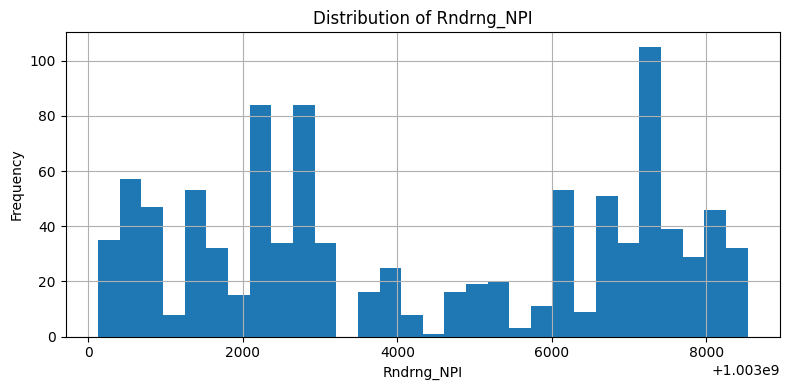

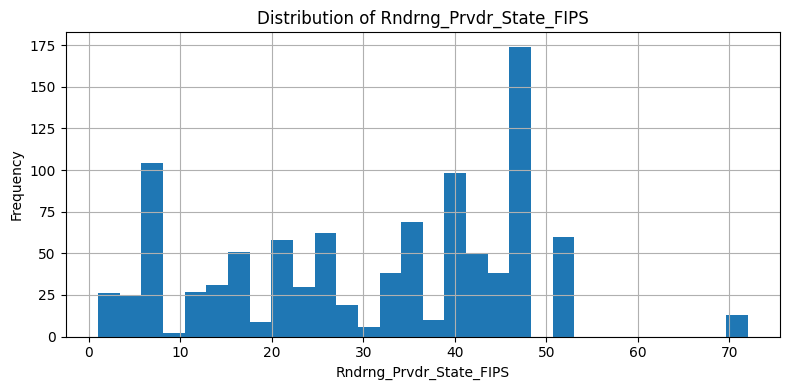

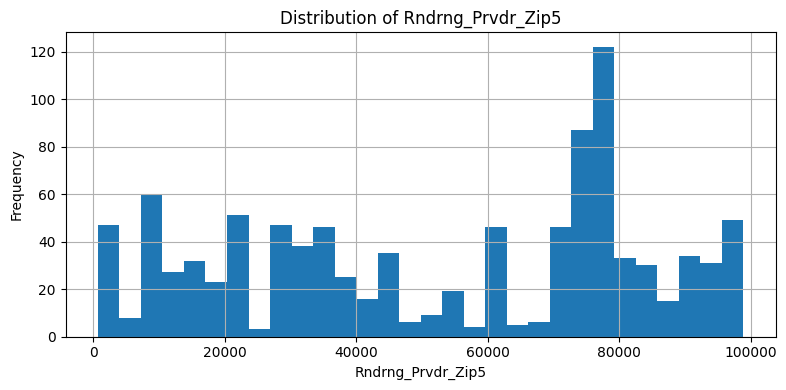

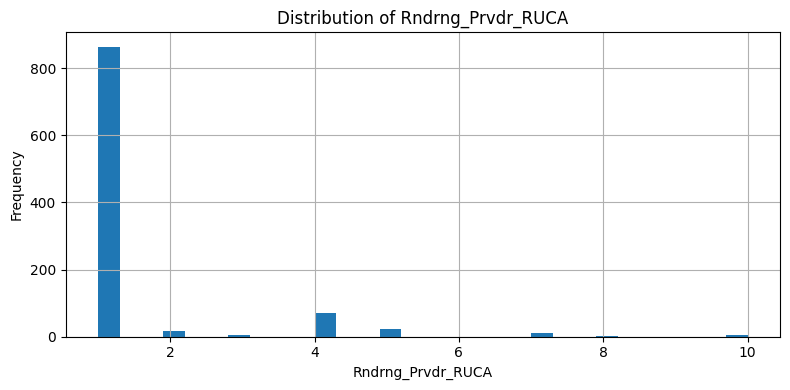

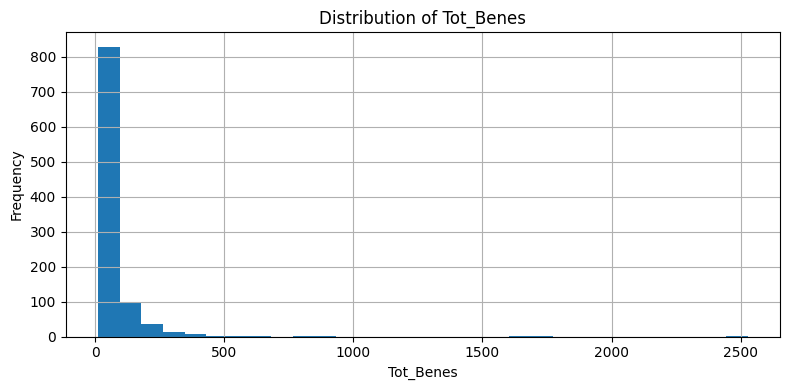

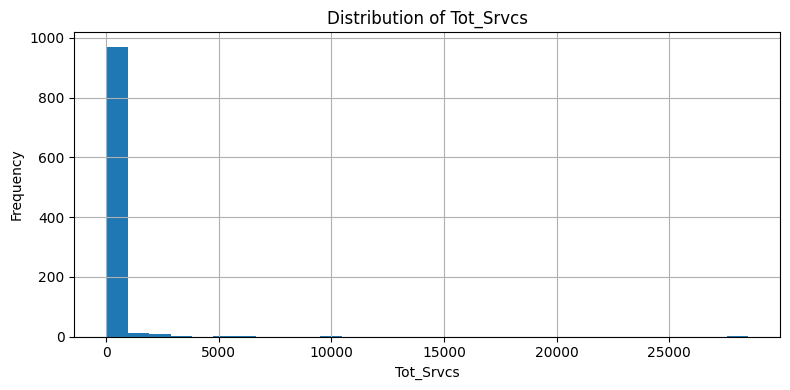

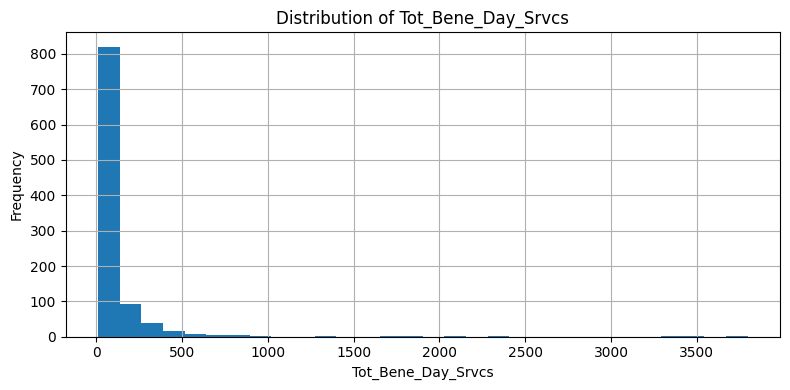

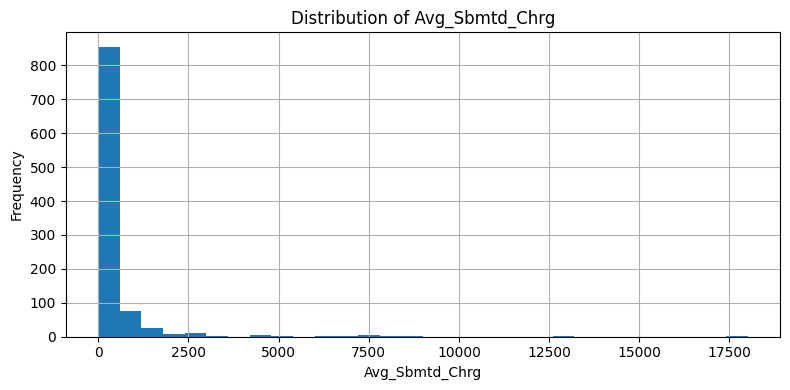

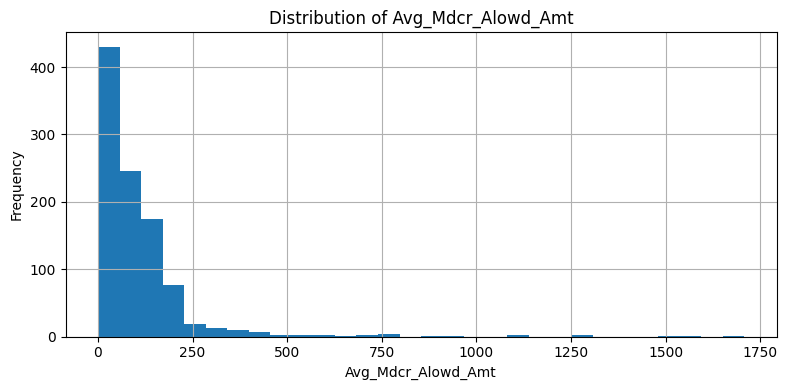

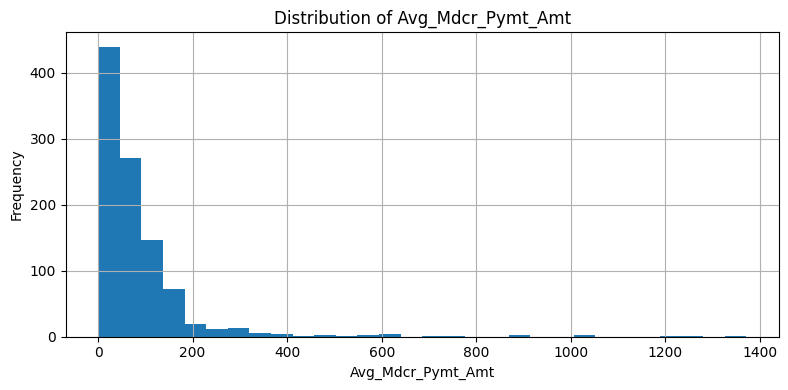

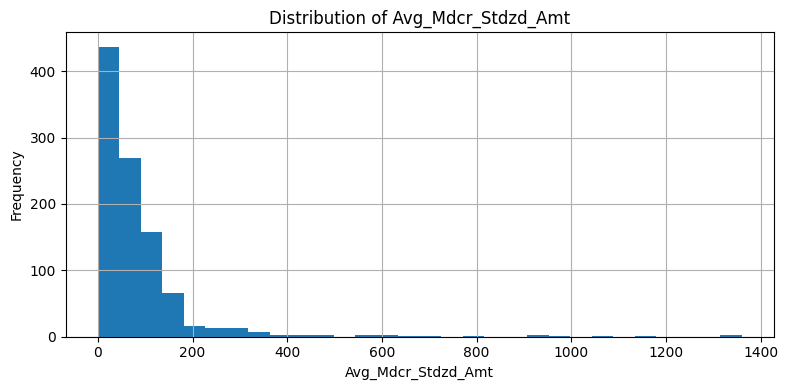

In [26]:
import matplotlib.pyplot as plt

numeric_columns = numeric_df.columns.tolist()

for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    cms_df[column].dropna().hist(bins=30)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [27]:
REPORT_DIR = PROJECT_DIR / "outputs" / "metrics"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

missing_analysis.to_csv(
    REPORT_DIR / "cms_2024_missing_values.csv"
)

numeric_df.describe().T.to_csv(
    REPORT_DIR / "cms_2024_numeric_summary.csv"
)

quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Missing Cells"
    ],
    "Value": [
        len(cms_df),
        len(cms_df.columns),
        int(cms_df.duplicated().sum()),
        int(cms_df.isnull().sum().sum())
    ]
})

quality_summary.to_csv(
    REPORT_DIR / "cms_2024_quality_summary.csv",
    index=False
)

print("Data quality reports saved successfully!")

Data quality reports saved successfully!


# Step 7: Data Cleaning and Preprocessing

Objectives:
1. Load the original CMS sample.
2. Standardize column names.
3. Convert numerical fields into appropriate data types.
4. Handle missing and suppressed values.
5. Identify duplicate records.
6. Check invalid numerical values.
7. Save the cleaned dataset separately.

In [28]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

raw_file = RAW_DIR / "cms_2024_sample.csv"

cms_df = pd.read_csv(raw_file, low_memory=False)

print("Original dataset loaded")
print("Shape:", cms_df.shape)

display(cms_df.head())

Original dataset loaded
Shape: (1000, 28)


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857


In [29]:
cms_df.columns = (
    cms_df.columns
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

print("Standardized column names:")
print(cms_df.columns.tolist())

Standardized column names:
['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']


In [30]:
numeric_candidates = [
    "Tot_Benes",
    "Tot_Srvcs",
    "Tot_Bene_Day_Srvcs",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Pymt_Amt"
]

numeric_columns = [
    column for column in numeric_candidates
    if column in cms_df.columns
]

for column in numeric_columns:
    cms_df[column] = pd.to_numeric(
        cms_df[column],
        errors="coerce"
    )

print("Numeric columns converted:")
print(numeric_columns)

Numeric columns converted:
['Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt']


In [31]:
missing_report = pd.DataFrame({
    "Missing_Count": cms_df.isna().sum(),
    "Missing_Percentage": (
        cms_df.isna().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Rndrng_Prvdr_St2,696,69.6
Rndrng_Prvdr_MI,358,35.8
Rndrng_Prvdr_Crdntls,74,7.4
Rndrng_Prvdr_First_Name,36,3.6
Rndrng_NPI,0,0.0
Rndrng_Prvdr_Last_Org_Name,0,0.0
Rndrng_Prvdr_Ent_Cd,0,0.0
Rndrng_Prvdr_St1,0,0.0
Rndrng_Prvdr_City,0,0.0
Rndrng_Prvdr_State_Abrvtn,0,0.0


In [32]:
duplicate_count = cms_df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

cms_clean = cms_df.drop_duplicates().copy()

print("Before removing duplicates:", len(cms_df))
print("After removing duplicates:", len(cms_clean))

Duplicate rows: 0
Before removing duplicates: 1000
After removing duplicates: 1000


In [33]:
for column in numeric_columns:
    print(f"\nChecking {column}")

    negative_count = (
        cms_clean[column].lt(0).sum()
    )

    print("Negative values:", negative_count)

    print(
        "Minimum:",
        cms_clean[column].min()
    )

    print(
        "Maximum:",
        cms_clean[column].max()
    )


Checking Tot_Benes
Negative values: 0
Minimum: 11
Maximum: 2527

Checking Tot_Srvcs
Negative values: 0
Minimum: 11.0
Maximum: 28487.8

Checking Tot_Bene_Day_Srvcs
Negative values: 0
Minimum: 11
Maximum: 3796

Checking Avg_Sbmtd_Chrg
Negative values: 0
Minimum: 0.13
Maximum: 18000.0

Checking Avg_Mdcr_Alowd_Amt
Negative values: 0
Minimum: 0.1062286011
Maximum: 1707.54875

Checking Avg_Mdcr_Pymt_Amt
Negative values: 0
Minimum: 0.082826087
Maximum: 1371.39


In [34]:
cleaned_file = (
    PROCESSED_DIR / "cms_2024_sample_cleaned.csv"
)

cms_clean.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File:", cleaned_file)
print("Final shape:", cms_clean.shape)

Cleaned dataset saved successfully!
File: /content/drive/MyDrive/healthcare-fraud-xai/data/processed/cms_2024_sample_cleaned.csv
Final shape: (1000, 28)


In [35]:
preprocessing_report = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Cleaned Rows",
        "Original Columns",
        "Removed Exact Duplicates",
        "Remaining Missing Cells"
    ],
    "Value": [
        len(cms_df),
        len(cms_clean),
        len(cms_df.columns),
        duplicate_count,
        int(cms_clean.isna().sum().sum())
    ]
})

display(preprocessing_report)

report_file = (
    PROJECT_DIR / "outputs" / "metrics"
    / "cms_2024_preprocessing_report.csv"
)

report_file.parent.mkdir(parents=True, exist_ok=True)

preprocessing_report.to_csv(
    report_file,
    index=False
)

print("Preprocessing report saved:", report_file)

,Metric,Value
0,Original Rows,1000
1,Cleaned Rows,1000
2,Original Columns,28
3,Removed Exact Duplicates,0
4,Remaining Missing Cells,1164


Preprocessing report saved: /content/drive/MyDrive/healthcare-fraud-xai/outputs/metrics/cms_2024_preprocessing_report.csv


# Step 8: Exploratory Data Analysis

Objectives:
1. Understand numerical distributions.
2. Analyze healthcare service utilization.
3. Examine submitted charges and Medicare payments.
4. Investigate relationships between billing variables.
5. Identify potential statistical anomalies.
6. Save visualizations and statistical summaries.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

CLEAN_FILE = (
    PROJECT_DIR / "data" / "processed"
    / "cms_2024_sample_cleaned.csv"
)

if not CLEAN_FILE.exists():
    raise FileNotFoundError(
        "Cleaned sample not found. Complete Step 7 first."
    )

cms_clean = pd.read_csv(CLEAN_FILE, low_memory=False)

print("Cleaned CMS dataset loaded!")
print("Rows:", len(cms_clean))
print("Columns:", len(cms_clean.columns))

display(cms_clean.head())

Cleaned CMS dataset loaded!
Rows: 1000
Columns: 28


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857


In [37]:
candidate_features = [
    "Tot_Benes",
    "Tot_Srvcs",
    "Tot_Bene_Day_Srvcs",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Pymt_Amt",
    "Avg_Mdcr_Stdzd_Amt"
]

available_features = [
    col for col in candidate_features
    if col in cms_clean.columns
]

print("Available research variables:")
print(available_features)

if not available_features:
    raise ValueError(
        "None of the expected numerical variables were found. "
        "Inspect the actual CMS column names."
    )

for col in available_features:
    cms_clean[col] = pd.to_numeric(
        cms_clean[col],
        errors="coerce"
    )

Available research variables:
['Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']


In [38]:
utilization_features = [
    col for col in [
        "Tot_Benes",
        "Tot_Srvcs",
        "Tot_Bene_Day_Srvcs"
    ]
    if col in cms_clean.columns
]

utilization_summary = (
    cms_clean[utilization_features]
    .describe()
    .T
)

display(utilization_summary)

,count,mean,std,min,25%,50%,75%,max
Tot_Benes,1000.0,68.3050,145.373028,11.0,17.0,29.5,69.0,2527.0
Tot_Srvcs,1000.0,197.7748,1059.456863,11.0,20.0,41.0,113.0,28487.8
Tot_Bene_Day_Srvcs,1000.0,112.8510,281.755136,11.0,20.0,37.0,100.0,3796.0


In [39]:
financial_features = [
    col for col in [
        "Avg_Sbmtd_Chrg",
        "Avg_Mdcr_Alowd_Amt",
        "Avg_Mdcr_Pymt_Amt",
        "Avg_Mdcr_Stdzd_Amt"
    ]
    if col in cms_clean.columns
]

financial_summary = (
    cms_clean[financial_features]
    .describe()
    .T
)

display(financial_summary)

,count,mean,std,min,25%,50%,75%,max
Avg_Sbmtd_Chrg,1000.0,466.302783,1172.301798,0.130000,71.000000,183.034091,396.087302,18000.00000
Avg_Mdcr_Alowd_Amt,1000.0,107.003349,152.318744,0.106229,29.373821,77.382053,130.117011,1707.54875
Avg_Mdcr_Pymt_Amt,1000.0,83.530088,121.526952,0.082826,22.094674,56.840584,99.425635,1371.39000
Avg_Mdcr_Stdzd_Amt,1000.0,84.047406,123.053866,0.082913,23.800104,58.204545,98.718214,1360.04875


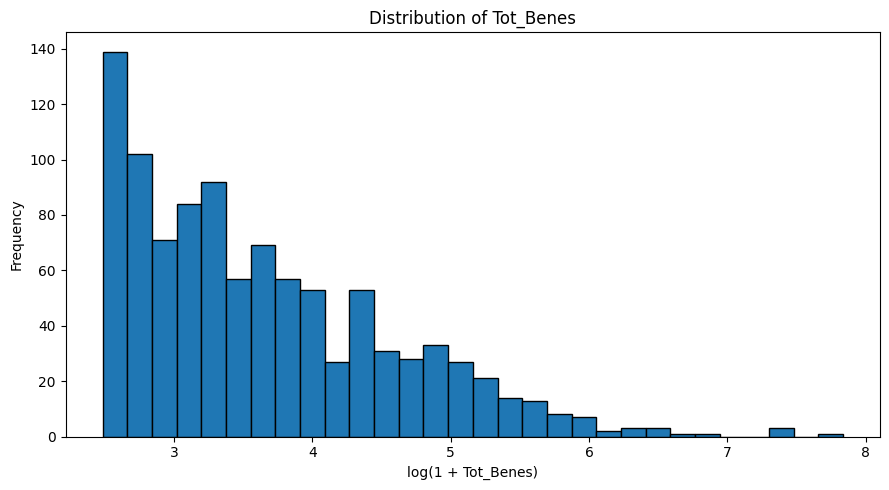

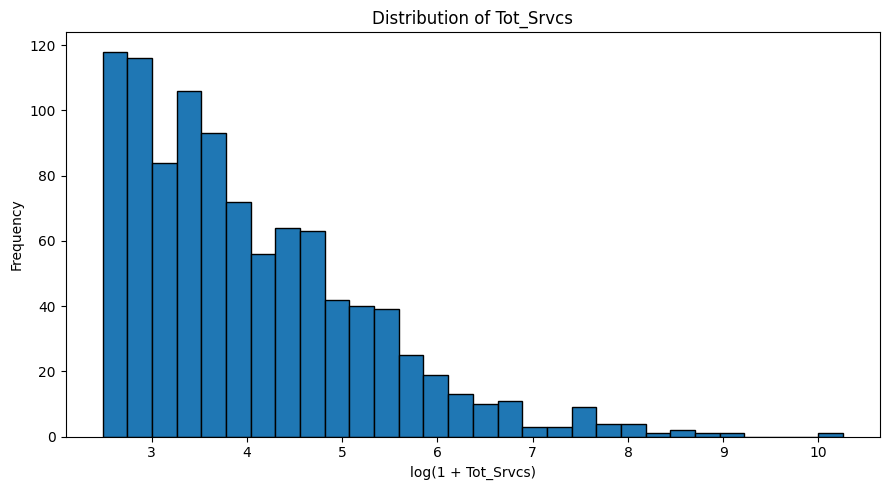

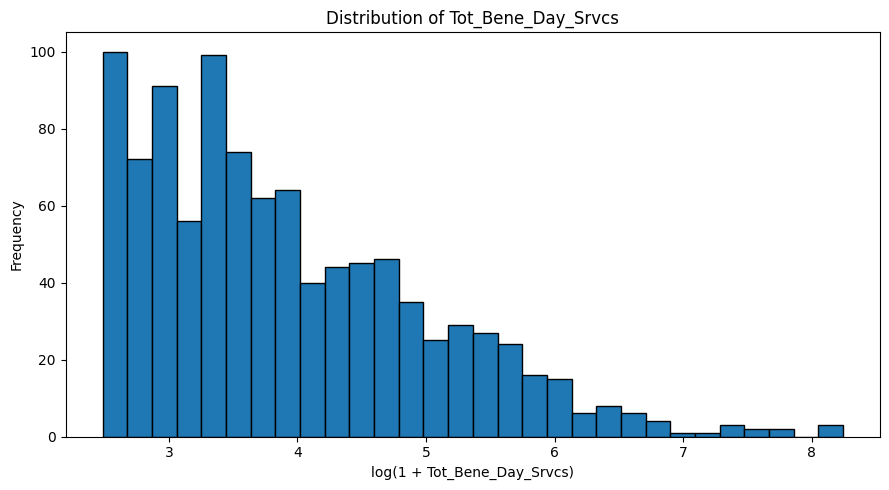

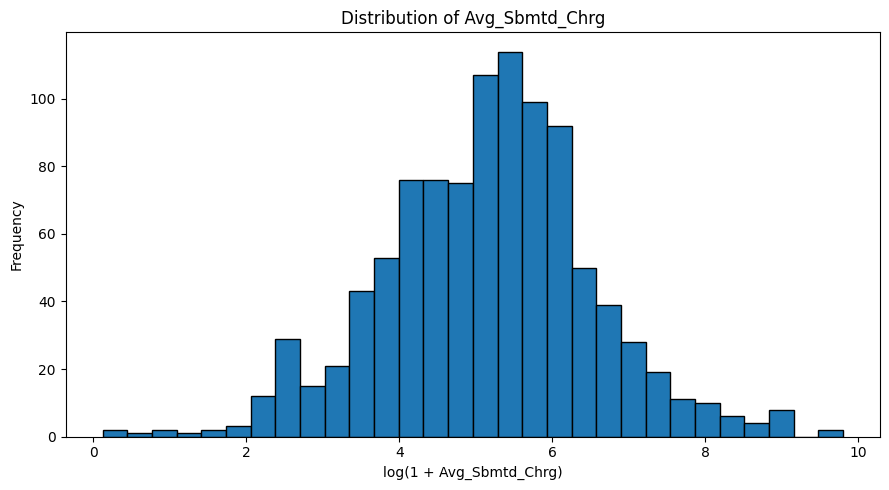

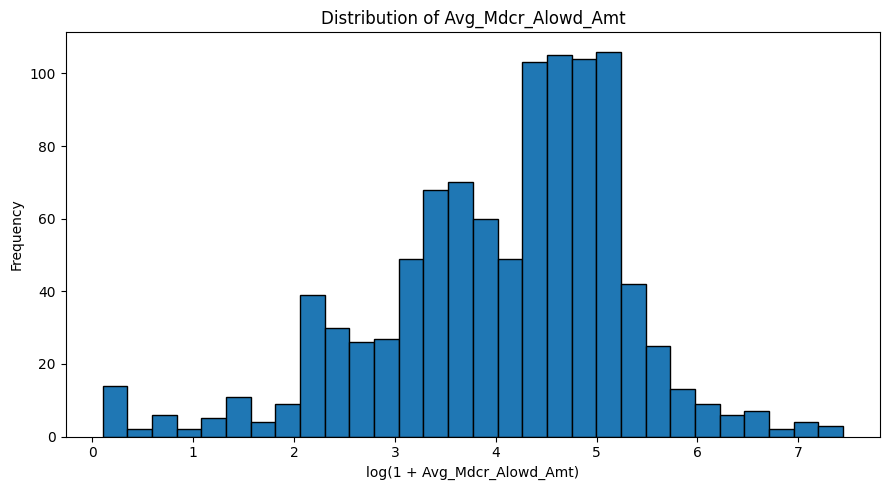

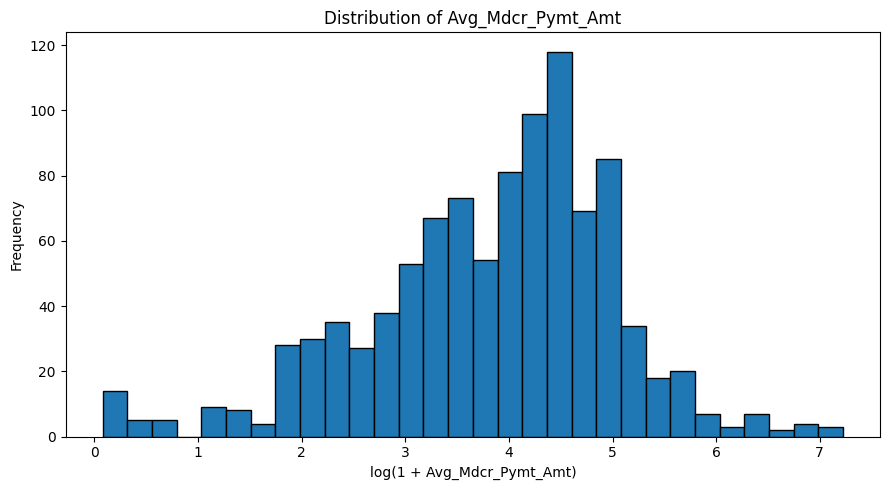

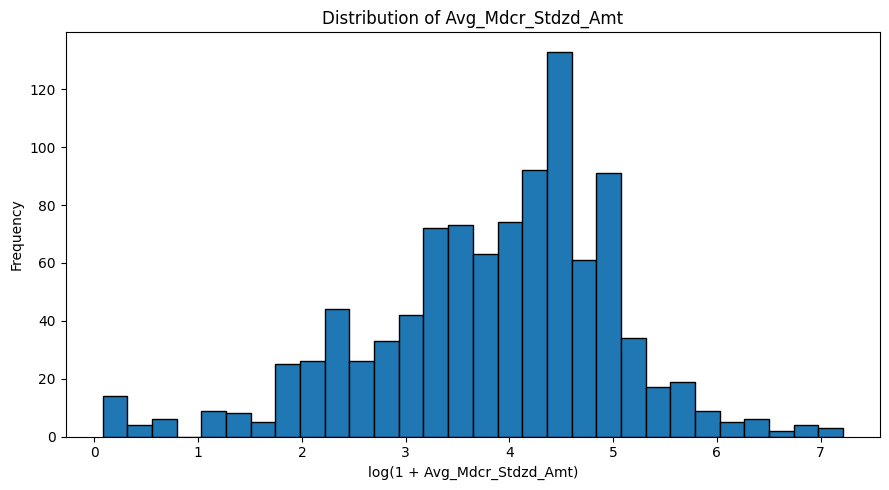

In [40]:
for column in available_features:

    values = cms_clean[column].dropna()

    plt.figure(figsize=(9, 5))

    if (values >= 0).all():
        plt.hist(
            np.log1p(values),
            bins=30,
            edgecolor="black"
        )
        plt.xlabel(f"log(1 + {column})")
    else:
        plt.hist(
            values,
            bins=30,
            edgecolor="black"
        )
        plt.xlabel(column)

    plt.title(f"Distribution of {column}")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

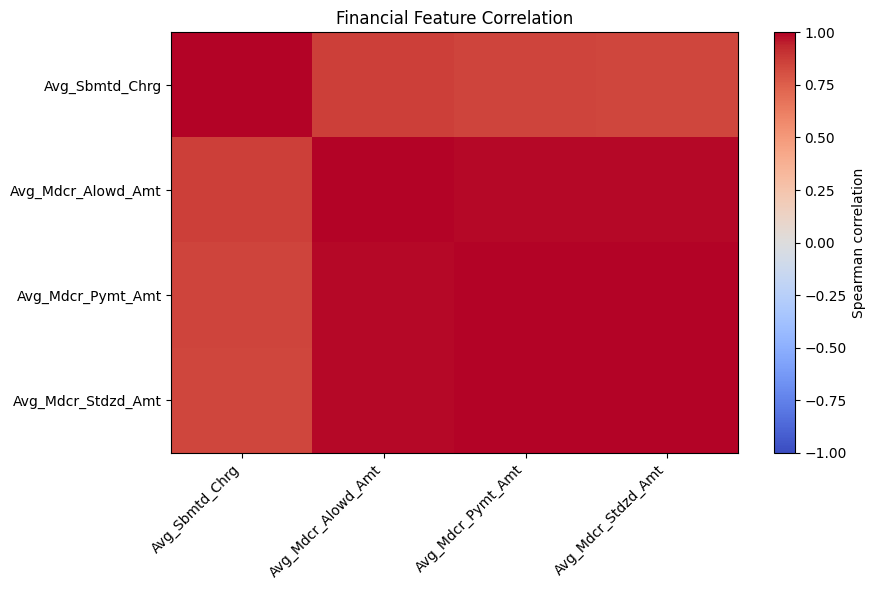

,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
Avg_Sbmtd_Chrg,1.000000,0.865069,0.848369,0.843042
Avg_Mdcr_Alowd_Amt,0.865069,1.000000,0.991551,0.989931
Avg_Mdcr_Pymt_Amt,0.848369,0.991551,1.000000,0.996343
Avg_Mdcr_Stdzd_Amt,0.843042,0.989931,0.996343,1.000000


In [41]:
financial_data = cms_clean[financial_features].dropna()

if len(financial_features) >= 2:

    correlation_matrix = financial_data.corr(
        method="spearman"
    )

    plt.figure(figsize=(9, 6))

    plt.imshow(
        correlation_matrix,
        aspect="auto",
        vmin=-1,
        vmax=1,
        cmap="coolwarm"
    )

    plt.colorbar(label="Spearman correlation")

    plt.xticks(
        range(len(financial_features)),
        financial_features,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(financial_features)),
        financial_features
    )

    plt.title("Financial Feature Correlation")
    plt.tight_layout()
    plt.show()

    display(correlation_matrix)
else:
    print("Not enough financial variables for correlation analysis.")

In [42]:
if "Place_Of_Srvc" in cms_clean.columns:

    place_summary = (
        cms_clean.groupby("Place_Of_Srvc")
        .agg(
            Records=("Place_Of_Srvc", "size"),
            Total_Beneficiaries=(
                "Tot_Benes", "sum"
            ) if "Tot_Benes" in cms_clean.columns
            else ("Place_Of_Srvc", "size"),
            Total_Services=(
                "Tot_Srvcs", "sum"
            ) if "Tot_Srvcs" in cms_clean.columns
            else ("Place_Of_Srvc", "size")
        )
        .reset_index()
    )

    display(place_summary)

else:
    print("Place_Of_Srvc is not available in this dataset.")

,Place_Of_Srvc,Records,Total_Beneficiaries,Total_Services
0,F,335,26038,58700.8
1,O,665,42267,139074.0


In [43]:
outlier_results = []

for column in available_features:

    values = cms_clean[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_results.append({
        "Feature": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(outliers.sum()),
        "Outlier_Percentage": round(
            outliers.mean() * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Tot_Benes,-61.000000,147.000000,101,10.1
1,Tot_Srvcs,-119.500000,252.500000,118,11.8
2,Tot_Bene_Day_Srvcs,-100.000000,220.000000,112,11.2
3,Avg_Sbmtd_Chrg,-416.630952,883.718254,98,9.8
4,Avg_Mdcr_Alowd_Amt,-121.740965,281.231796,53,5.3
5,Avg_Mdcr_Pymt_Amt,-93.901767,215.422077,59,5.9
6,Avg_Mdcr_Stdzd_Amt,-88.577061,211.095379,61,6.1


In [44]:
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
METRICS_DIR = OUTPUT_DIR / "metrics"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

utilization_summary.to_csv(
    METRICS_DIR / "cms_2024_utilization_summary.csv"
)

financial_summary.to_csv(
    METRICS_DIR / "cms_2024_financial_summary.csv"
)

outlier_report.to_csv(
    METRICS_DIR / "cms_2024_outlier_report.csv",
    index=False
)

if len(financial_features) >= 2:
    correlation_matrix.to_csv(
        METRICS_DIR / "cms_2024_financial_correlations.csv"
    )

print("EDA reports saved successfully!")

EDA reports saved successfully!


# Step 9: Feature Engineering

Objectives:
1. Create service utilization features.
2. Calculate charge and payment ratios.
3. Examine provider-service billing patterns.
4. Handle division-by-zero cases.
5. Save the engineered dataset.

In [45]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

CLEAN_FILE = (
    PROJECT_DIR / "data" / "processed"
    / "cms_2024_sample_cleaned.csv"
)

cms_clean = pd.read_csv(CLEAN_FILE, low_memory=False)

print("Dataset loaded:", cms_clean.shape)

display(cms_clean.head())

Dataset loaded: (1000, 28)


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857


In [46]:
required_columns = [
    "Tot_Benes",
    "Tot_Srvcs",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Pymt_Amt"
]

available_columns = [
    col for col in required_columns
    if col in cms_clean.columns
]

missing_columns = [
    col for col in required_columns
    if col not in cms_clean.columns
]

print("Available columns:", available_columns)
print("Missing columns:", missing_columns)

Available columns: ['Tot_Benes', 'Tot_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt']
Missing columns: []


In [47]:
if {"Tot_Srvcs", "Tot_Benes"}.issubset(cms_clean.columns):

    cms_clean["Services_Per_Beneficiary"] = (
        cms_clean["Tot_Srvcs"] /
        cms_clean["Tot_Benes"].replace(0, np.nan)
    )

if {
    "Tot_Bene_Day_Srvcs",
    "Tot_Benes"
}.issubset(cms_clean.columns):

    cms_clean["Beneficiary_Day_Services_Per_Beneficiary"] = (
        cms_clean["Tot_Bene_Day_Srvcs"] /
        cms_clean["Tot_Benes"].replace(0, np.nan)
    )

print("Service utilization features created.")

display(
    cms_clean.filter(
        regex="Services_Per_Beneficiary"
    ).head()
)

Service utilization features created.


,Services_Per_Beneficiary,Beneficiary_Day_Services_Per_Beneficiary
0,1.000000,1.000000
1,1.000000,1.000000
2,1.000000,1.000000
3,1.454545,1.454545
4,1.891892,1.891892


In [48]:
if {
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt"
}.issubset(cms_clean.columns):

    cms_clean["Charge_To_Allowed_Ratio"] = (
        cms_clean["Avg_Sbmtd_Chrg"] /
        cms_clean["Avg_Mdcr_Alowd_Amt"].replace(0, np.nan)
    )

In [49]:
if {
    "Avg_Mdcr_Pymt_Amt",
    "Avg_Mdcr_Alowd_Amt"
}.issubset(cms_clean.columns):

    cms_clean["Payment_To_Allowed_Ratio"] = (
        cms_clean["Avg_Mdcr_Pymt_Amt"] /
        cms_clean["Avg_Mdcr_Alowd_Amt"].replace(0, np.nan)
    )

In [50]:
if {
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt"
}.issubset(cms_clean.columns):

    cms_clean["Charge_Allowed_Difference"] = (
        cms_clean["Avg_Sbmtd_Chrg"] -
        cms_clean["Avg_Mdcr_Alowd_Amt"]
    )

In [51]:
engineered_features = [
    "Services_Per_Beneficiary",
    "Beneficiary_Day_Services_Per_Beneficiary",
    "Charge_To_Allowed_Ratio",
    "Payment_To_Allowed_Ratio",
    "Charge_Allowed_Difference"
]

existing_engineered_features = [
    col for col in engineered_features
    if col in cms_clean.columns
]

print("New features created:")
print(existing_engineered_features)

display(
    cms_clean[existing_engineered_features].describe().T
)

New features created:
['Services_Per_Beneficiary', 'Beneficiary_Day_Services_Per_Beneficiary', 'Charge_To_Allowed_Ratio', 'Payment_To_Allowed_Ratio', 'Charge_Allowed_Difference']


,count,mean,std,min,25%,50%,75%,max
Services_Per_Beneficiary,1000.0,3.748635,25.574482,1.000000,1.000000,1.066667,1.487901,714.285714
Beneficiary_Day_Services_Per_Beneficiary,1000.0,1.710546,2.559404,1.000000,1.000000,1.042455,1.353992,33.705882
Charge_To_Allowed_Ratio,1000.0,6.002056,31.245227,0.961052,1.904728,2.707129,4.080921,885.547201
Payment_To_Allowed_Ratio,1000.0,0.783079,0.097000,0.330603,0.740944,0.783395,0.797470,1.000000
Charge_Allowed_Difference,1000.0,359.299434,1084.387553,-2.310000,30.341807,109.926961,259.451538,16409.554242


In [52]:
for column in existing_engineered_features:

    cms_clean[column] = cms_clean[column].replace(
        [np.inf, -np.inf],
        np.nan
    )

print("Infinite values remaining:")
print(
    np.isinf(
        cms_clean[existing_engineered_features]
    ).sum()
)

print("\nMissing values in engineered features:")
display(cms_clean[existing_engineered_features].isna().sum())

Infinite values remaining:
Services_Per_Beneficiary                    0
Beneficiary_Day_Services_Per_Beneficiary    0
Charge_To_Allowed_Ratio                     0
Payment_To_Allowed_Ratio                    0
Charge_Allowed_Difference                   0
dtype: int64

Missing values in engineered features:


,0
Services_Per_Beneficiary,0
Beneficiary_Day_Services_Per_Beneficiary,0
Charge_To_Allowed_Ratio,0
Payment_To_Allowed_Ratio,0
Charge_Allowed_Difference,0


In [53]:
FEATURE_DIR = PROJECT_DIR / "data" / "processed"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

feature_file = (
    FEATURE_DIR / "cms_2024_sample_engineered.csv"
)

cms_clean.to_csv(feature_file, index=False)

print("Feature engineering completed!")
print("Saved:", feature_file)
print("Final dimensions:", cms_clean.shape)

Feature engineering completed!
Saved: /content/drive/MyDrive/healthcare-fraud-xai/data/processed/cms_2024_sample_engineered.csv
Final dimensions: (1000, 33)


In [54]:
feature_descriptions = {
    "Services_Per_Beneficiary":
        "Total services divided by total beneficiaries",

    "Beneficiary_Day_Services_Per_Beneficiary":
        "Beneficiary day services divided by total beneficiaries",

    "Charge_To_Allowed_Ratio":
        "Submitted charge divided by Medicare allowed amount",

    "Payment_To_Allowed_Ratio":
        "Medicare payment divided by Medicare allowed amount",

    "Charge_Allowed_Difference":
        "Submitted charge minus Medicare allowed amount"
}

feature_report = pd.DataFrame([
    {
        "Feature": feature,
        "Description": description
    }
    for feature, description in feature_descriptions.items()
    if feature in cms_clean.columns
])

feature_report.to_csv(
    PROJECT_DIR / "outputs" / "metrics"
    / "cms_2024_feature_descriptions.csv",
    index=False
)

display(feature_report)

,Feature,Description
0,Services_Per_Beneficiary,Total services divided by total beneficiaries
1,Beneficiary_Day_Services_Per_Beneficiary,Beneficiary day services divided by total bene...
2,Charge_To_Allowed_Ratio,Submitted charge divided by Medicare allowed a...
3,Payment_To_Allowed_Ratio,Medicare payment divided by Medicare allowed a...
4,Charge_Allowed_Difference,Submitted charge minus Medicare allowed amount


## Step 11: Historical CMS Release Verification

We are verifying the annual CMS Provider and Service datasets
for 2018–2024.

Only confirmed identifiers will be used for data acquisition.

In [55]:

import pandas as pd
import requests
from pathlib import Path

CMS_RELEASES = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3",
}

def validate_cms_release(year, dataset_id):

    api_url = (
        f"https://data.cms.gov/data-api/v1/dataset/"
        f"{dataset_id}/data"
    )

    dictionary_url = (
        f"https://data.cms.gov/data-api/v1/dataset/"
        f"{dataset_id}/dictionary"
    )

    result = {
        "year": year,
        "dataset_id": dataset_id,
        "api_status": "NOT TESTED",
        "dictionary_status": "NOT TESTED",
        "sample_rows": 0,
        "columns": 0
    }

    try:
        response = requests.get(
            api_url,
            params={"size": 2, "offset": 0},
            timeout=60
        )

        response.raise_for_status()
        records = response.json()

        if not isinstance(records, list) or not records:
            raise ValueError("No sample records returned")

        result["api_status"] = "SUCCESS"
        result["sample_rows"] = len(records)
        result["columns"] = len(records[0].keys())

        result["column_names"] = list(records[0].keys())

    except Exception as error:
        result["api_status"] = f"FAILED: {error}"

    try:
        dictionary_response = requests.get(
            dictionary_url,
            timeout=60
        )

        dictionary_response.raise_for_status()
        result["dictionary_status"] = "SUCCESS"

    except Exception as error:
        result["dictionary_status"] = f"FAILED: {error}"

    return result


validation_results = []

for year, dataset_id in CMS_RELEASES.items():

    print(f"Validating {year} release...")

    validation_results.append(
        validate_cms_release(year, dataset_id)
    )

validation_df = pd.DataFrame(validation_results)

display(validation_df)


Validating 2018 release...
Validating 2023 release...
Validating 2024 release...


,year,dataset_id,api_status,dictionary_status,sample_rows,columns,column_names
0,2018,fb6d9fe8-38c1-4d24-83d4-0b7b291000b2,SUCCESS,SUCCESS,2,28,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."
1,2023,0e9f2f2b-7bf9-451a-912c-e02e654dd725,SUCCESS,SUCCESS,2,28,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."
2,2024,335e5f35-eca6-482d-87b3-f99883e213e3,SUCCESS,SUCCESS,2,28,"[Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrn..."


In [56]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

METADATA_DIR = PROJECT_DIR / "data" / "external"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

manifest_file = (
    METADATA_DIR / "cms_release_validation.csv"
)

validation_df.to_csv(manifest_file, index=False)

print("Manifest saved:", manifest_file)

Manifest saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_release_validation.csv


In [57]:
cms_2024_columns = validation_df.loc[
    validation_df["year"] == 2024,
    "column_names"
].iloc[0]

print("Actual 2024 CMS columns:")
for column in cms_2024_columns:
    print("-", column)

Actual 2024 CMS columns:
- Rndrng_NPI
- Rndrng_Prvdr_Last_Org_Name
- Rndrng_Prvdr_First_Name
- Rndrng_Prvdr_MI
- Rndrng_Prvdr_Crdntls
- Rndrng_Prvdr_Ent_Cd
- Rndrng_Prvdr_St1
- Rndrng_Prvdr_St2
- Rndrng_Prvdr_City
- Rndrng_Prvdr_State_Abrvtn
- Rndrng_Prvdr_State_FIPS
- Rndrng_Prvdr_Zip5
- Rndrng_Prvdr_RUCA
- Rndrng_Prvdr_RUCA_Desc
- Rndrng_Prvdr_Cntry
- Rndrng_Prvdr_Type
- Rndrng_Prvdr_Mdcr_Prtcptg_Ind
- HCPCS_Cd
- HCPCS_Desc
- HCPCS_Drug_Ind
- Place_Of_Srvc
- Tot_Benes
- Tot_Srvcs
- Tot_Bene_Day_Srvcs
- Avg_Sbmtd_Chrg
- Avg_Mdcr_Alowd_Amt
- Avg_Mdcr_Pymt_Amt
- Avg_Mdcr_Stdzd_Amt


# Step 12: CMS Data Dictionary and Feature Verification

Objectives:
1. Retrieve the official CMS data dictionary.
2. Inspect actual variable names.
3. Identify numerical and categorical fields.
4. Verify the proposed research features.
5. Save the data dictionary for reproducibility.

In [58]:

import requests
import json
import pandas as pd
from pathlib import Path

CMS_2024_ID = "335e5f35-eca6-482d-87b3-f99883e213e3"

DICTIONARY_URL = (
    f"https://data.cms.gov/data-api/v1/dataset/"
    f"{CMS_2024_ID}/dictionary"
)

response = requests.get(
    DICTIONARY_URL,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

cms_dictionary = response.json()

print("Dictionary retrieved successfully!")
print("Response type:", type(cms_dictionary).__name__)

print(json.dumps(cms_dictionary, indent=2)[:12000])


HTTP Status: 200
Dictionary retrieved successfully!
Response type: dict
{
  "identifier": "b065f387-8c72-4aa9-8394-2780648f2522",
  "data": {
    "title": "Medicare Physician & Other Practitioners - by Provider and Service Data Dictionary",
    "fields": [
      {
        "name": "Rndrng_NPI",
        "label": "National Provider Identifier",
        "description": "National Provider Identifier (NPI) for the rendering provider on the claim. The provider NPI is the numeric identifier registered in NPPES."
      },
      {
        "name": "Rndrng_Prvdr_Last_Org_Name",
        "label": "Last Name/Organization Name of the Provider",
        "description": "When the provider is registered in NPPES as an individual (entity type code=\u2019I\u2019), this is the provider\u2019s last name. When the provider is registered as an organization (entity type code = \u2018O\u2019), this is the organization name."
      },
      {
        "name": "Rndrng_Prvdr_First_Name",
        "label": "First Name o

In [59]:
# Inspect the actual dataset columns
CMS_API_URL = (
    f"https://data.cms.gov/data-api/v1/dataset/"
    f"{CMS_2024_ID}/data"
)

response = requests.get(
    CMS_API_URL,
    params={"size": 5, "offset": 0},
    timeout=60
)

response.raise_for_status()

cms_records = response.json()

if not cms_records:
    raise ValueError("CMS returned no records.")

actual_columns = list(cms_records[0].keys())

print("Verified CMS columns:")
for column in actual_columns:
    print("-", column)

Verified CMS columns:
- Rndrng_NPI
- Rndrng_Prvdr_Last_Org_Name
- Rndrng_Prvdr_First_Name
- Rndrng_Prvdr_MI
- Rndrng_Prvdr_Crdntls
- Rndrng_Prvdr_Ent_Cd
- Rndrng_Prvdr_St1
- Rndrng_Prvdr_St2
- Rndrng_Prvdr_City
- Rndrng_Prvdr_State_Abrvtn
- Rndrng_Prvdr_State_FIPS
- Rndrng_Prvdr_Zip5
- Rndrng_Prvdr_RUCA
- Rndrng_Prvdr_RUCA_Desc
- Rndrng_Prvdr_Cntry
- Rndrng_Prvdr_Type
- Rndrng_Prvdr_Mdcr_Prtcptg_Ind
- HCPCS_Cd
- HCPCS_Desc
- HCPCS_Drug_Ind
- Place_Of_Srvc
- Tot_Benes
- Tot_Srvcs
- Tot_Bene_Day_Srvcs
- Avg_Sbmtd_Chrg
- Avg_Mdcr_Alowd_Amt
- Avg_Mdcr_Pymt_Amt
- Avg_Mdcr_Stdzd_Amt


In [60]:
identifier_candidates = [
    "Rndrng_NPI",
    "HCPCS_Cd",
    "Place_Of_Srvc"
]

numeric_candidates = [
    "Tot_Benes",
    "Tot_Srvcs",
    "Tot_Bene_Day_Srvcs",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Pymt_Amt"
]

verified_identifiers = [
    col for col in identifier_candidates
    if col in actual_columns
]

verified_numeric_candidates = [
    col for col in numeric_candidates
    if col in actual_columns
]

print("Verified identifiers:")
print(verified_identifiers)

print("\nVerified numerical candidates:")
print(verified_numeric_candidates)

print("\nUnverified numerical candidates:")
print([
    col for col in numeric_candidates
    if col not in actual_columns
])

Verified identifiers:
['Rndrng_NPI', 'HCPCS_Cd', 'Place_Of_Srvc']

Verified numerical candidates:
['Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt']

Unverified numerical candidates:
[]


In [61]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

OUTPUT_DIR = PROJECT_DIR / "data" / "external"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

column_report = pd.DataFrame({
    "Column": actual_columns,
    "Is_Identifier": [
        col in verified_identifiers
        for col in actual_columns
    ],
    "Is_Numeric_Candidate": [
        col in verified_numeric_candidates
        for col in actual_columns
    ]
})

column_report.to_csv(
    OUTPUT_DIR / "cms_2024_verified_columns.csv",
    index=False
)

with open(
    OUTPUT_DIR / "cms_2024_dictionary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(cms_dictionary, file, indent=4)

print("CMS verification files saved successfully.")

CMS verification files saved successfully.


# Step 13: Historical CMS Release Inventory

Research period: 2018–2024

Dataset:
Medicare Physician & Other Practitioners - by Provider and Service

Goal:
Identify and verify every annual release before downloading.

In [62]:

import requests
import pandas as pd

# Official CMS Provider and Service series
SERIES_ID = "92396110-2aed-4d63-a6a2-5d6207d46a29"

SERIES_URL = (
    f"https://data.cms.gov/data-api/v1/dataset/"
    f"{SERIES_ID}/data"
)

print("Connecting to the CMS annual dataset series...")

response = requests.get(
    SERIES_URL,
    params={"size": 2, "offset": 0},
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

records = response.json()

print("Records returned:", len(records))

if records:
    print("\nFirst record:")
    display(pd.DataFrame(records).head())
else:
    print("No records returned from the series endpoint.")


Connecting to the CMS annual dataset series...
HTTP Status: 200
Records returned: 2

First record:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36,36,284.37888889,79.063888889,60.828888889,62.376388889
1,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150,150,352.17633333,126.3408,95.6756,96.007133333


In [63]:

# Known release identifiers for the exact Provider and Service dataset.
# These are candidates for validation, not automatically accepted releases.

CANDIDATE_RELEASES = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3",
}

def test_release(year, dataset_id):

    url = (
        f"https://data.cms.gov/data-api/v1/dataset/"
        f"{dataset_id}/data"
    )

    try:
        r = requests.get(
            url,
            params={"size": 1, "offset": 0},
            timeout=60
        )

        r.raise_for_status()
        data = r.json()

        if not data:
            return {
                "year": year,
                "identifier": dataset_id,
                "status": "EMPTY"
            }

        return {
            "year": year,
            "identifier": dataset_id,
            "status": "VALID",
            "sample_records": len(data),
            "columns": len(data[0])
        }

    except Exception as e:
        return {
            "year": year,
            "identifier": dataset_id,
            "status": str(e)
        }

release_inventory = pd.DataFrame([
    test_release(year, dataset_id)
    for year, dataset_id in CANDIDATE_RELEASES.items()
])

display(release_inventory)


,year,identifier,status,sample_records,columns
0,2018,fb6d9fe8-38c1-4d24-83d4-0b7b291000b2,VALID,1,28
1,2023,0e9f2f2b-7bf9-451a-912c-e02e654dd725,VALID,1,28
2,2024,335e5f35-eca6-482d-87b3-f99883e213e3,VALID,1,28


In [64]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

METADATA_DIR = PROJECT_DIR / "data" / "external"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

inventory_path = (
    METADATA_DIR / "cms_historical_release_inventory.csv"
)

release_inventory.to_csv(inventory_path, index=False)

print("Inventory saved:", inventory_path)

Inventory saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_historical_release_inventory.csv


# Step 14: Historical CMS Data Download Pipeline

Objectives:
1. Download verified annual CMS datasets.
2. Save original CSV files in Google Drive.
3. Record file sizes and checksums.
4. Track successful and unsuccessful downloads.
5. Preserve original datasets without modifying them.

In [65]:

import requests
import hashlib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)


def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


def download_cms_csv(year, csv_url):

    output_file = RAW_DIR / f"cms_{year}_provider_service.csv"

    print(f"\nDownloading CMS {year} dataset...")

    try:
        with requests.get(
            csv_url,
            stream=True,
            timeout=(30, 300)
        ) as response:

            response.raise_for_status()

            total_size = int(
                response.headers.get("content-length", 0)
            )

            temporary_file = output_file.with_suffix(".part")

            with open(temporary_file, "wb") as file:
                with tqdm(
                    total=total_size if total_size else None,
                    unit="B",
                    unit_scale=True,
                    desc=str(year)
                ) as progress:

                    for chunk in response.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            file.write(chunk)
                            progress.update(len(chunk))

            temporary_file.replace(output_file)

        checksum = calculate_sha256(output_file)

        print("Download successful:", output_file)
        print(
            "File size (MB):",
            round(output_file.stat().st_size / (1024 ** 2), 2)
        )

        return {
            "year": year,
            "file": str(output_file),
            "size_mb": round(
                output_file.stat().st_size / (1024 ** 2), 2
            ),
            "sha256": checksum,
            "status": "SUCCESS"
        }

    except Exception as error:

        if output_file.with_suffix(".part").exists():
            output_file.with_suffix(".part").unlink()

        print(f"Download failed for {year}:", error)

        return {
            "year": year,
            "file": None,
            "size_mb": None,
            "sha256": None,
            "status": f"FAILED: {error}"
        }


In [66]:
VERIFIED_CMS_URLS = {
    2018: (
        "https://data.cms.gov/sites/default/files/"
        "2025-11/5669eafb-f0b3-4dc5-be6d-abc09b480c2e/"
        "MUP_PHY_R25_P04_V20_D18_Prov_Svc.csv"
    ),

    2023: (
        "https://data.cms.gov/sites/default/files/"
        "2025-04/e3f823f8-db5b-4cc7-ba04-e7ae92b99757/"
        "MUP_PHY_R25_P05_V20_D23_Prov_Svc.csv"
    ),

    2024: (
        "https://data.cms.gov/sites/default/files/"
        "2026-05/b5ebab5a-f490-418a-9bce-4b9f31419356/"
        "PHY_R26_P05_V10_D24_Prov_Svc.csv"
    )
}

print("Verified annual CSV URLs:", list(VERIFIED_CMS_URLS))

Verified annual CSV URLs: [2018, 2023, 2024]


In [67]:
download_result_2024 = download_cms_csv(
    2024,
    VERIFIED_CMS_URLS[2024]
)

display(pd.DataFrame([download_result_2024]))

2024:   0%|          | 0.00/3.25G [00:00<?, ?B/s]

Download successful: /content/drive/MyDrive/healthcare-fraud-xai/data/raw/cms_2024_provider_service.csv
File size (MB): 3099.71


,year,file,size_mb,sha256,status
0,2024,/content/drive/MyDrive/healthcare-fraud-xai/da...,3099.71,509dc7ce4cd02d8dd160d50d33ce5d942cd120ea306ff1...,SUCCESS


In [68]:
downloaded_file = (
    RAW_DIR / "cms_2024_provider_service.csv"
)

if not downloaded_file.exists():
    raise FileNotFoundError("CMS 2024 CSV was not downloaded.")

print("File exists:", downloaded_file.exists())

print(
    "File size (MB):",
    round(downloaded_file.stat().st_size / (1024 ** 2), 2)
)

print("SHA-256:")
print(calculate_sha256(downloaded_file))

print("\nFirst five rows:")
cms_download_check = pd.read_csv(
    downloaded_file,
    nrows=5,
    low_memory=False
)

display(cms_download_check)

File exists: True
File size (MB): 3099.71
SHA-256:
509dc7ce4cd02d8dd160d50d33ce5d942cd120ea306ff1eb2b6ece4f59cb2c23

First five rows:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70,70,583.606857,81.428571,62.728714,58.486857


In [69]:
download_manifest = pd.DataFrame([
    download_result_2024
])

manifest_path = (
    PROJECT_DIR / "data" / "external"
    / "cms_download_manifest.csv"
)

manifest_path.parent.mkdir(parents=True, exist_ok=True)

download_manifest.to_csv(
    manifest_path,
    index=False
)

print("Download manifest saved:", manifest_path)

Download manifest saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_download_manifest.csv


# Step 15: Full Dataset Validation

Dataset: CMS 2024 Provider and Service

Objectives:
- Verify the downloaded CSV.
- Count records and columns.
- Inspect data types.
- Analyze missing values.
- Check duplicate records.
- Generate a validation report.

In [70]:

from pathlib import Path
import pandas as pd
import hashlib

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"

CSV_FILE = RAW_DIR / "cms_2024_provider_service.csv"

if not CSV_FILE.exists():
    raise FileNotFoundError(
        "The full 2024 CMS CSV was not found. "
        "Complete Step 14 before proceeding."
    )

print("File found:", CSV_FILE)
print(
    "File size (MB):",
    round(CSV_FILE.stat().st_size / (1024 ** 2), 2)
)


File found: /content/drive/MyDrive/healthcare-fraud-xai/data/raw/cms_2024_provider_service.csv
File size (MB): 3099.71


In [71]:
cms_columns_df = pd.read_csv(
    CSV_FILE,
    nrows=5,
    low_memory=False
)

print("COLUMN NAMES:")
print(cms_columns_df.columns.tolist())

print("\nFIRST FIVE RECORDS:")
display(cms_columns_df.head())

print("\nDATA TYPES:")
display(cms_columns_df.dtypes.to_frame("Data Type"))

COLUMN NAMES:
['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']

FIRST FIVE RECORDS:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70,70,583.606857,81.428571,62.728714,58.486857



DATA TYPES:


,Data Type
Rndrng_NPI,int64
Rndrng_Prvdr_Last_Org_Name,object
Rndrng_Prvdr_First_Name,object
Rndrng_Prvdr_MI,float64
Rndrng_Prvdr_Crdntls,object
Rndrng_Prvdr_Ent_Cd,object
Rndrng_Prvdr_St1,object
Rndrng_Prvdr_St2,float64
Rndrng_Prvdr_City,object
Rndrng_Prvdr_State_Abrvtn,object


In [72]:
total_rows = 0
chunk_size = 100000

for chunk in pd.read_csv(
    CSV_FILE,
    chunksize=chunk_size,
    low_memory=False
):
    total_rows += len(chunk)

print("Total records:", total_rows)
print("Total columns:", len(cms_columns_df.columns))

Total records: 9781673
Total columns: 28


In [73]:
missing_counts = pd.Series(
    0,
    index=cms_columns_df.columns,
    dtype="int64"
)

for chunk in pd.read_csv(
    CSV_FILE,
    chunksize=chunk_size,
    low_memory=False
):
    missing_counts = missing_counts.add(
        chunk.isna().sum(),
        fill_value=0
    )

missing_report = pd.DataFrame({
    "Missing_Count": missing_counts.astype(int),
    "Missing_Percentage": (
        missing_counts / total_rows * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Rndrng_Prvdr_St2,7637996,78.08
Rndrng_Prvdr_MI,3465045,35.42
Rndrng_Prvdr_Crdntls,1079707,11.04
Rndrng_Prvdr_First_Name,474867,4.85
Rndrng_Prvdr_RUCA_Desc,5291,0.05
Rndrng_Prvdr_RUCA,5291,0.05
Rndrng_NPI,0,0.00
Rndrng_Prvdr_Last_Org_Name,0,0.00
Rndrng_Prvdr_City,0,0.00
Rndrng_Prvdr_State_Abrvtn,0,0.00


In [74]:
import hashlib

seen_hashes = set()
duplicate_count = 0

for chunk in pd.read_csv(
    CSV_FILE,
    chunksize=chunk_size,
    low_memory=False
):

    row_hashes = pd.util.hash_pandas_object(
        chunk,
        index=False
    )

    for value in row_hashes:
        value = int(value)

        if value in seen_hashes:
            duplicate_count += 1
        else:
            seen_hashes.add(value)

print("Exact duplicate rows detected:", duplicate_count)

Exact duplicate rows detected: 0


In [75]:
def calculate_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


file_checksum = calculate_sha256(CSV_FILE)

print("SHA-256 checksum:")
print(file_checksum)

SHA-256 checksum:
509dc7ce4cd02d8dd160d50d33ce5d942cd120ea306ff1eb2b6ece4f59cb2c23


In [76]:
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

validation_summary = pd.DataFrame({
    "Metric": [
        "Dataset Year",
        "Total Records",
        "Total Columns",
        "File Size MB",
        "Exact Duplicate Rows",
        "Missing Cells",
        "SHA256"
    ],
    "Value": [
        2024,
        total_rows,
        len(cms_columns_df.columns),
        round(CSV_FILE.stat().st_size / (1024 ** 2), 2),
        duplicate_count,
        int(missing_counts.sum()),
        file_checksum
    ]
})

display(validation_summary)

validation_summary.to_csv(
    METRICS_DIR / "cms_2024_full_validation.csv",
    index=False
)

missing_report.to_csv(
    METRICS_DIR / "cms_2024_full_missing_report.csv"
)

print("Validation reports saved successfully.")

,Metric,Value
0,Dataset Year,2024
1,Total Records,9781673
2,Total Columns,28
3,File Size MB,3099.71
4,Exact Duplicate Rows,0
5,Missing Cells,12668203
6,SHA256,509dc7ce4cd02d8dd160d50d33ce5d942cd120ea306ff1...


Validation reports saved successfully.


# Step 16: Historical CMS Release Inventory

Target period: 2018–2024

Dataset: Medicare Physician & Other Practitioners - by Provider and Service

All annual releases must be verified before merging.

In [77]:

import pandas as pd
from pathlib import Path

release_inventory = pd.DataFrame([
    {"year": 2018, "status": "IDENTIFIER FOUND - VALIDATION REQUIRED"},
    {"year": 2019, "status": "IDENTIFIER PENDING"},
    {"year": 2020, "status": "IDENTIFIER PENDING"},
    {"year": 2021, "status": "IDENTIFIER PENDING"},
    {"year": 2022, "status": "IDENTIFIER PENDING"},
    {"year": 2023, "status": "IDENTIFIER FOUND - VALIDATION REQUIRED"},
    {"year": 2024, "status": "IDENTIFIER FOUND - VALIDATION REQUIRED"},
])

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

METADATA_DIR = PROJECT_DIR / "data" / "external"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

inventory_file = (
    METADATA_DIR / "cms_2018_2024_release_inventory.csv"
)

release_inventory.to_csv(inventory_file, index=False)

display(release_inventory)

print("\nInventory saved:", inventory_file)


,year,status
0,2018,IDENTIFIER FOUND - VALIDATION REQUIRED
1,2019,IDENTIFIER PENDING
2,2020,IDENTIFIER PENDING
3,2021,IDENTIFIER PENDING
4,2022,IDENTIFIER PENDING
5,2023,IDENTIFIER FOUND - VALIDATION REQUIRED
6,2024,IDENTIFIER FOUND - VALIDATION REQUIRED



Inventory saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_2018_2024_release_inventory.csv


In [78]:
 from pathlib import Path
import pandas as pd

RAW_DIR = PROJECT_DIR / "data" / "raw"

csv_file = RAW_DIR / "cms_2024_provider_service.csv"

if not csv_file.exists():
    raise FileNotFoundError(
        "2024 full CSV not found. Complete Step 14 first."
    )

sample = pd.read_csv(
    csv_file,
    nrows=100,
    low_memory=False
)

schema_report = pd.DataFrame({
    "Column": sample.columns,
    "Data_Type": [
        str(sample[col].dtype)
        for col in sample.columns
    ],
    "Missing_In_Sample": [
        int(sample[col].isna().sum())
        for col in sample.columns
    ]
})

schema_file = METADATA_DIR / "cms_2024_schema_reference.csv"

schema_report.to_csv(schema_file, index=False)

display(schema_report)

print("2024 schema reference saved:", schema_file)

,Column,Data_Type,Missing_In_Sample
0,Rndrng_NPI,int64,0
1,Rndrng_Prvdr_Last_Org_Name,object,0
2,Rndrng_Prvdr_First_Name,object,0
3,Rndrng_Prvdr_MI,object,34
4,Rndrng_Prvdr_Crdntls,object,0
5,Rndrng_Prvdr_Ent_Cd,object,0
6,Rndrng_Prvdr_St1,object,0
7,Rndrng_Prvdr_St2,object,30
8,Rndrng_Prvdr_City,object,0
9,Rndrng_Prvdr_State_Abrvtn,object,0


2024 schema reference saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_2024_schema_reference.csv


# Step 17: Automated Historical CMS Release Discovery

Dataset: Medicare Physician & Other Practitioners - by Provider and Service

Research period: 2018–2024

Source: Official CMS data catalog

Objective:
Automatically identify annual API identifiers and CSV download URLs.

In [79]:

import requests
import pandas as pd
import re

CMS_CATALOG_URL = "https://data.cms.gov/data.json"

SERIES_ID = "92396110-2aed-4d63-a6a2-5d6207d46a29"

print("Connecting to the CMS catalog...")

response = requests.get(
    CMS_CATALOG_URL,
    timeout=180
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

catalog = response.json()

datasets = catalog.get(
    "dataset",
    catalog.get("@graph", [])
)

if isinstance(datasets, dict):
    datasets = [datasets]

print("Catalog records retrieved:", len(datasets))


Connecting to the CMS catalog...
HTTP Status: 200
Catalog records retrieved: 3508


In [80]:

release_records = []

for item in datasets:

    title = item.get("title", "")

    # Check exact dataset family
    if "by provider and service" not in title.lower():
        continue

    # Check relationship to the correct annual series
    series_info = item.get("inSeries", [])

    if isinstance(series_info, dict):
        series_info = [series_info]

    belongs_to_series = any(
        SERIES_ID in str(series.get("@id", ""))
        for series in series_info
    )

    if not belongs_to_series:
        continue

    year_match = re.search(r"20\d{2}", title)

    if not year_match:
        continue

    year = int(year_match.group())

    if year < 2018 or year > 2024:
        continue

    distributions = item.get("distribution", [])

    if isinstance(distributions, dict):
        distributions = [distributions]

    api_url = None
    csv_url = None

    for resource in distributions:

        file_format = str(
            resource.get("format", "")
        ).upper()

        if file_format == "API":
            api_url = resource.get("accessURL")

        elif file_format == "CSV":
            csv_url = resource.get("downloadURL")

    release_records.append({
        "year": year,
        "dataset_title": title,
        "api_url": api_url,
        "csv_url": csv_url
    })

historical_releases = pd.DataFrame(release_records)

if historical_releases.empty:
    print("No annual releases were discovered.")
else:
    historical_releases = (
        historical_releases
        .drop_duplicates(subset=["year"])
        .sort_values("year")
        .reset_index(drop=True)
    )

    display(historical_releases)

    print("\nYears discovered:")
    print(historical_releases["year"].tolist())


,year,dataset_title,api_url,csv_url
0,2018,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/fb6d9...,https://data.cms.gov/sites/default/files/2025-...
1,2019,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/867b8...,https://data.cms.gov/sites/default/files/2025-...
2,2020,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/c957b...,https://data.cms.gov/sites/default/files/2025-...
3,2021,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/31dc2...,https://data.cms.gov/sites/default/files/2025-...
4,2022,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/e6509...,https://data.cms.gov/sites/default/files/2025-...
5,2023,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/0e9f2...,https://data.cms.gov/sites/default/files/2025-...
6,2024,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/335e5...,https://data.cms.gov/sites/default/files/2026-...



Years discovered:
[2018, 2019, 2020, 2021, 2022, 2023, 2024]


In [81]:
expected_years = set(range(2018, 2025))

if not historical_releases.empty:

    discovered_years = set(
        historical_releases["year"].astype(int)
    )

    missing_years = sorted(
        expected_years - discovered_years
    )

    print("Discovered years:", sorted(discovered_years))
    print("Missing years:", missing_years)

    if not missing_years:
        print("All seven annual releases were discovered.")
    else:
        print("Historical release discovery is incomplete.")

Discovered years: [2018, 2019, 2020, 2021, 2022, 2023, 2024]
Missing years: []
All seven annual releases were discovered.


In [82]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/healthcare-fraud-xai"
)

METADATA_DIR = PROJECT_DIR / "data" / "external"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = (
    METADATA_DIR / "cms_2018_2024_release_manifest.csv"
)

historical_releases.to_csv(
    manifest_path,
    index=False
)

print("Manifest saved:", manifest_path)

Manifest saved: /content/drive/MyDrive/healthcare-fraud-xai/data/external/cms_2018_2024_release_manifest.csv


In [83]:

import requests
import pandas as pd
import json
import re
from datetime import datetime

# --------------------------------------------------
# STEP 18: CMS RELEASE VALIDATION
# --------------------------------------------------

SERIES_ID = "92396110-2aed-4d63-a6a2-5d6207d46a29"

# These three release IDs were previously identified
# for the exact Provider and Service dataset.
known_releases = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3"
}

BASE_URL = "https://data.cms.gov/data-api/v1/dataset"

session = requests.Session()
session.headers.update({
    "User-Agent": "Healthcare-Fraud-XAI-Research/1.0"
})

validation_results = []

for year, dataset_id in known_releases.items():

    print(f"\nValidating release: {year}")
    print("-" * 50)

    api_url = f"{BASE_URL}/{dataset_id}/data?size=1&offset=0"
    dictionary_url = f"{BASE_URL}/{dataset_id}/data-dictionary"

    result = {
        "year": year,
        "dataset_id": dataset_id,
        "api_status": "Not checked",
        "dictionary_status": "Not checked",
        "sample_rows": 0,
        "columns": "",
        "validation_status": "FAILED"
    }

    try:
        response = session.get(api_url, timeout=60)
        response.raise_for_status()

        sample = response.json()

        if isinstance(sample, list) and len(sample) > 0:
            sample_df = pd.DataFrame(sample)
        elif isinstance(sample, dict):
            records = sample.get("data", sample.get("results", []))
            sample_df = pd.DataFrame(records)
        else:
            sample_df = pd.DataFrame()

        if sample_df.empty:
            raise ValueError("The API returned no sample rows.")

        result["api_status"] = "SUCCESS"
        result["sample_rows"] = len(sample_df)
        result["columns"] = ", ".join(sample_df.columns.astype(str))

        print("API: SUCCESS")
        print("Sample rows:", len(sample_df))
        print("Columns:", list(sample_df.columns))

    except Exception as error:
        result["api_status"] = f"FAILED: {error}"
        print("API validation failed:", error)

    try:
        dictionary_response = session.get(
            dictionary_url,
            timeout=60
        )
        dictionary_response.raise_for_status()

        dictionary_data = dictionary_response.json()

        if not dictionary_data:
            raise ValueError("The data dictionary is empty.")

        result["dictionary_status"] = "SUCCESS"
        print("Data dictionary: SUCCESS")

    except Exception as error:
        result["dictionary_status"] = f"FAILED: {error}"
        print("Dictionary validation failed:", error)

    if (
        result["api_status"] == "SUCCESS"
        and result["dictionary_status"] == "SUCCESS"
    ):
        result["validation_status"] = "VALIDATED"

    validation_results.append(result)

# --------------------------------------------------
# DISPLAY VALIDATION RESULTS
# --------------------------------------------------

validation_df = pd.DataFrame(validation_results)

print("\nFINAL VALIDATION SUMMARY")
display(validation_df)

# Save the validation report
validation_path = (
    "/content/cms_known_release_validation.csv"
)

validation_df.to_csv(validation_path, index=False)

print("\nValidation report saved:", validation_path)



Validating release: 2018
--------------------------------------------------
API: SUCCESS
Sample rows: 1
Columns: ['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']
Dictionary validation failed: 404 Client Error: Not Found for url: https://data.cms.gov/data-api/v1/dataset/fb6d9fe8-38c1-4d24-83d4-0b7b291000b2/data-dictionary

Validating release: 2023
--------------------------------------------------
API: SUCCESS
Sample rows: 1
Columns: ['Rndrng_NPI', 'Rndr

,year,dataset_id,api_status,dictionary_status,sample_rows,columns,validation_status
0,2018,fb6d9fe8-38c1-4d24-83d4-0b7b291000b2,SUCCESS,FAILED: 404 Client Error: Not Found for url: h...,1,"Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrng...",FAILED
1,2023,0e9f2f2b-7bf9-451a-912c-e02e654dd725,SUCCESS,FAILED: 404 Client Error: Not Found for url: h...,1,"Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrng...",FAILED
2,2024,335e5f35-eca6-482d-87b3-f99883e213e3,SUCCESS,FAILED: 404 Client Error: Not Found for url: h...,1,"Rndrng_NPI, Rndrng_Prvdr_Last_Org_Name, Rndrng...",FAILED



Validation report saved: /content/cms_known_release_validation.csv


In [84]:

import requests
import pandas as pd
import json
from pathlib import Path

# --------------------------------------------------
# STEP 19: INSPECT CMS DATA DICTIONARIES
# --------------------------------------------------

releases = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3"
}

BASE_URL = "https://data.cms.gov/data-api/v1/dataset"

output_dir = Path("/content/cms_dictionary_audit")
output_dir.mkdir(exist_ok=True)

session = requests.Session()
session.headers.update({
    "User-Agent": "Healthcare-Fraud-XAI-Research/1.0"
})

dictionary_summary = []

for year, dataset_id in releases.items():

    print(f"\n{'=' * 60}")
    print(f"YEAR: {year}")
    print(f"{'=' * 60}")

    dictionary_url = f"{BASE_URL}/{dataset_id}/dictionary"

    try:
        response = session.get(dictionary_url, timeout=60)
        response.raise_for_status()

        dictionary = response.json()

        # Save the original dictionary for reference
        dictionary_file = output_dir / f"cms_dictionary_{year}.json"

        with open(dictionary_file, "w", encoding="utf-8") as file:
            json.dump(dictionary, file, indent=2)

        # CMS dictionary structures can vary.
        # Inspect the response rather than assuming one format.
        if isinstance(dictionary, list):
            fields = dictionary

        elif isinstance(dictionary, dict):
            fields = (
                dictionary.get("columns")
                or dictionary.get("fields")
                or dictionary.get("data")
                or []
            )

            if isinstance(fields, dict):
                fields = list(fields.values())

        else:
            fields = []

        print("Dictionary request: SUCCESS")
        print("Dictionary saved:", dictionary_file)

        if fields:
            for field in fields:
                if isinstance(field, dict):
                    name = (
                        field.get("name")
                        or field.get("field")
                        or field.get("column_name")
                        or field.get("label")
                    )

                    data_type = (
                        field.get("type")
                        or field.get("dataType")
                        or field.get("datatype")
                        or field.get("format")
                    )

                    description = (
                        field.get("description")
                        or field.get("definition")
                        or field.get("label")
                        or ""
                    )

                    dictionary_summary.append({
                        "year": year,
                        "column": name,
                        "data_type": data_type,
                        "description": description
                    })

            print("Fields detected:", len(fields))

        else:
            print("Could not identify the field list automatically.")
            print("Dictionary structure:")
            print(json.dumps(dictionary, indent=2)[:3000])

    except Exception as error:
        print(f"Dictionary request failed for {year}: {error}")

# --------------------------------------------------
# CREATE AUDIT TABLE
# --------------------------------------------------

audit_df = pd.DataFrame(dictionary_summary)

if not audit_df.empty:
    display(audit_df)

    audit_file = "/content/cms_dictionary_audit.csv"
    audit_df.to_csv(audit_file, index=False)

    print("\nAudit saved:", audit_file)

else:
    print("\nNo dictionary fields were extracted.")
    print("Check the dictionary response printed above.")



YEAR: 2018
Dictionary request: SUCCESS
Dictionary saved: /content/cms_dictionary_audit/cms_dictionary_2018.json
Fields detected: 2

YEAR: 2023
Dictionary request: SUCCESS
Dictionary saved: /content/cms_dictionary_audit/cms_dictionary_2023.json
Fields detected: 2

YEAR: 2024
Dictionary request: SUCCESS
Dictionary saved: /content/cms_dictionary_audit/cms_dictionary_2024.json
Fields detected: 2

No dictionary fields were extracted.
Check the dictionary response printed above.


In [85]:

import json
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# STEP 20: COMPARE ANNUAL CMS SCHEMAS
# --------------------------------------------------

dictionary_dir = Path("/content/cms_dictionary_audit")

years = [2018, 2023, 2024]

schemas = {}
missing_files = []

# Load dictionaries saved in Step 19
for year in years:

    file_path = dictionary_dir / f"cms_dictionary_{year}.json"

    if not file_path.exists():
        missing_files.append(year)
        continue

    with open(file_path, "r", encoding="utf-8") as file:
        dictionary = json.load(file)

    # Extract fields from common CMS dictionary structures
    if isinstance(dictionary, list):
        fields = dictionary

    elif isinstance(dictionary, dict):
        fields = (
            dictionary.get("columns")
            or dictionary.get("fields")
            or dictionary.get("data")
            or []
        )

        if isinstance(fields, dict):
            fields = list(fields.values())

    else:
        fields = []

    column_names = []

    for field in fields:
        if isinstance(field, dict):
            name = (
                field.get("name")
                or field.get("field")
                or field.get("column_name")
            )

            if name:
                column_names.append(str(name))

    if column_names:
        schemas[year] = set(column_names)
        print(f"{year}: {len(column_names)} columns extracted")
    else:
        print(f"{year}: Could not automatically extract columns.")

# --------------------------------------------------
# CHECK WHETHER ALL DICTIONARIES ARE AVAILABLE
# --------------------------------------------------

if missing_files:
    print("\nMissing dictionary files:", missing_files)
    print("Run Step 19 successfully before comparing schemas.")

elif len(schemas) != len(years):
    print("\nSchema comparison cannot be completed.")
    print("Some dictionaries did not contain recognizable field names.")

else:

    # --------------------------------------------------
    # COMMON AND YEAR-SPECIFIC COLUMNS
    # --------------------------------------------------

    common_columns = set.intersection(*schemas.values())
    all_columns = set.union(*schemas.values())

    print("\nCOMMON COLUMNS ACROSS ALL THREE YEARS")
    print("Number of common columns:", len(common_columns))

    common_df = pd.DataFrame({
        "column_name": sorted(common_columns)
    })

    display(common_df)

    print("\nYEAR-SPECIFIC COLUMN COMPARISON")

    comparison = []

    for column in sorted(all_columns):

        comparison.append({
            "column_name": column,
            "2018": column in schemas[2018],
            "2023": column in schemas[2023],
            "2024": column in schemas[2024]
        })

    comparison_df = pd.DataFrame(comparison)
    display(comparison_df)

    # --------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------

    common_df.to_csv(
        "/content/cms_common_columns.csv",
        index=False
    )

    comparison_df.to_csv(
        "/content/cms_schema_comparison.csv",
        index=False
    )

    print("\nSaved:")
    print("/content/cms_common_columns.csv")
    print("/content/cms_schema_comparison.csv")


2018: Could not automatically extract columns.
2023: Could not automatically extract columns.
2024: Could not automatically extract columns.

Schema comparison cannot be completed.
Some dictionaries did not contain recognizable field names.


In [86]:

import requests
import pandas as pd
import json
from pathlib import Path

# --------------------------------------------------
# STEP 21: INSPECT ACTUAL CMS DATA COLUMNS
# --------------------------------------------------

releases = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3"
}

BASE_URL = "https://data.cms.gov/data-api/v1/dataset"

session = requests.Session()
session.headers.update({
    "User-Agent": "Healthcare-Fraud-XAI-Research/1.0"
})

column_sets = {}
sample_records = {}

for year, dataset_id in releases.items():

    print(f"\nInspecting {year}")
    print("-" * 50)

    url = f"{BASE_URL}/{dataset_id}/data"

    try:
        response = session.get(
            url,
            params={"size": 5, "offset": 0},
            timeout=90
        )
        response.raise_for_status()

        records = response.json()

        if isinstance(records, dict):
            records = records.get(
                "data",
                records.get("results", [])
            )

        if not isinstance(records, list) or not records:
            print("No records returned. Check the API response.")
            continue

        sample_df = pd.DataFrame(records)

        column_sets[year] = set(sample_df.columns)
        sample_records[year] = sample_df

        print("Rows retrieved:", len(sample_df))
        print("Number of columns:", len(sample_df.columns))
        print("\nActual column names:")
        print(sample_df.columns.tolist())

        print("\nSample records:")
        display(sample_df.head(2))

    except Exception as error:
        print(f"Could not inspect {year}: {error}")

# --------------------------------------------------
# COMPARE ACTUAL COLUMNS
# --------------------------------------------------

if len(column_sets) >= 2:

    all_columns = set.union(*column_sets.values())

    comparison = []

    for column in sorted(all_columns):

        row = {"column_name": column}

        for year in releases:
            row[str(year)] = (
                column in column_sets.get(year, set())
            )

        comparison.append(row)

    actual_schema_df = pd.DataFrame(comparison)

    print("\nACTUAL COLUMN COMPARISON")
    display(actual_schema_df)

    actual_schema_df.to_csv(
        "/content/cms_actual_column_comparison.csv",
        index=False
    )

    print("Saved: /content/cms_actual_column_comparison.csv")

else:
    print(
        "\nNot enough successful releases to compare columns. "
        "Resolve the API errors before proceeding."
    )



Inspecting 2018
--------------------------------------------------
Rows retrieved: 5
Number of columns: 28

Actual column names:
['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']

Sample records:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,,M.D.,I,900 Seton Dr,,Cumberland,MD,...,Hospital observation care on day of discharge,N,F,67,68,68,381.30882353,72.641029412,57.880294118,58.2125
1,1003000126,Enkeshafi,Ardalan,,M.D.,I,900 Seton Dr,,Cumberland,MD,...,"Hospital observation care, typically 30 minutes",N,F,19,19,19,476.94736842,99.311578947,76.795263158,77.469473684



Inspecting 2023
--------------------------------------------------
Rows retrieved: 5
Number of columns: 28

Actual column names:
['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']

Sample records:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,12,12,12,250.22666667,89.0625,60.3125,54.669166667
1,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,22,22,22,318.58181818,130.31272727,99.38,98.429545455



Inspecting 2024
--------------------------------------------------
Rows retrieved: 5
Number of columns: 28

Actual column names:
['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']

Sample records:


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36,36,284.37888889,79.063888889,60.828888889,62.376388889
1,1003000126,Enkeshafi,Ardalan,,M.D.,I,6410 Rockledge Dr Ste 304,,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150,150,352.17633333,126.3408,95.6756,96.007133333



ACTUAL COLUMN COMPARISON


,column_name,2018,2023,2024
0,Avg_Mdcr_Alowd_Amt,True,True,True
1,Avg_Mdcr_Pymt_Amt,True,True,True
2,Avg_Mdcr_Stdzd_Amt,True,True,True
3,Avg_Sbmtd_Chrg,True,True,True
4,HCPCS_Cd,True,True,True
5,HCPCS_Desc,True,True,True
6,HCPCS_Drug_Ind,True,True,True
7,Place_Of_Srvc,True,True,True
8,Rndrng_NPI,True,True,True
9,Rndrng_Prvdr_City,True,True,True


Saved: /content/cms_actual_column_comparison.csv


In [87]:

import pandas as pd
from pathlib import Path

# --------------------------------------------------
# STEP 22: IDENTIFY RESEARCH VARIABLES
# --------------------------------------------------

if "column_sets" not in globals() or not column_sets:
    raise RuntimeError(
        "Step 21 data is not available. "
        "Run Step 21 successfully first."
    )

# Research variable groups and common CMS naming patterns.
# These are search patterns, not confirmed CMS field names.

variable_patterns = {
    "provider_id": [
        "npi", "provider"
    ],
    "procedure_code": [
        "hcpcs", "procedure", "service_code"
    ],
    "place_of_service": [
        "place_of_srvc", "place_of_service", "pos"
    ],
    "beneficiary_count": [
        "bene", "beneficiary", "patient"
    ],
    "service_count": [
        "srvcs", "services", "service_count"
    ],
    "submitted_charges": [
        "sbmtd_chrg", "submitted_charge", "charge"
    ],
    "allowed_amount": [
        "alowd_amt", "allowed_amt", "allowed_amount"
    ],
    "medicare_payment": [
        "mdcr_pymt", "medicare_payment", "payment"
    ],
    "year": [
        "year", "period"
    ]
}

# --------------------------------------------------
# FIND CANDIDATE COLUMNS FOR EACH YEAR
# --------------------------------------------------

mapping_rows = []

for year, columns in column_sets.items():

    print(f"\nChecking year: {year}")

    normalized_columns = {
        column: str(column).lower()
        for column in columns
    }

    for variable, patterns in variable_patterns.items():

        matches = []

        for original_column, normalized_column in normalized_columns.items():

            if any(
                pattern in normalized_column
                for pattern in patterns
            ):
                matches.append(original_column)

        mapping_rows.append({
            "year": year,
            "research_variable": variable,
            "candidate_columns": ", ".join(matches),
            "candidate_count": len(matches)
        })

        print(f"{variable}: {matches if matches else 'No match found'}")

# --------------------------------------------------
# CREATE MAPPING REPORT
# --------------------------------------------------

mapping_df = pd.DataFrame(mapping_rows)

print("\nRESEARCH VARIABLE MAPPING REPORT")
display(mapping_df)

output_path = "/content/cms_research_variable_mapping.csv"

mapping_df.to_csv(output_path, index=False)

print("\nMapping report saved:", output_path)



Checking year: 2018
provider_id: ['Rndrng_NPI']
procedure_code: ['HCPCS_Desc', 'HCPCS_Drug_Ind', 'HCPCS_Cd']
place_of_service: ['Place_Of_Srvc']
beneficiary_count: ['Tot_Bene_Day_Srvcs', 'Tot_Benes']
service_count: ['Tot_Srvcs', 'Tot_Bene_Day_Srvcs']
submitted_charges: ['Avg_Sbmtd_Chrg']
allowed_amount: ['Avg_Mdcr_Alowd_Amt']
medicare_payment: ['Avg_Mdcr_Pymt_Amt']
year: No match found

Checking year: 2023
provider_id: ['Rndrng_NPI']
procedure_code: ['HCPCS_Desc', 'HCPCS_Drug_Ind', 'HCPCS_Cd']
place_of_service: ['Place_Of_Srvc']
beneficiary_count: ['Tot_Bene_Day_Srvcs', 'Tot_Benes']
service_count: ['Tot_Srvcs', 'Tot_Bene_Day_Srvcs']
submitted_charges: ['Avg_Sbmtd_Chrg']
allowed_amount: ['Avg_Mdcr_Alowd_Amt']
medicare_payment: ['Avg_Mdcr_Pymt_Amt']
year: No match found

Checking year: 2024
provider_id: ['Rndrng_NPI']
procedure_code: ['HCPCS_Desc', 'HCPCS_Drug_Ind', 'HCPCS_Cd']
place_of_service: ['Place_Of_Srvc']
beneficiary_count: ['Tot_Bene_Day_Srvcs', 'Tot_Benes']
service_count: ['To

,year,research_variable,candidate_columns,candidate_count
0,2018,provider_id,Rndrng_NPI,1
1,2018,procedure_code,"HCPCS_Desc, HCPCS_Drug_Ind, HCPCS_Cd",3
2,2018,place_of_service,Place_Of_Srvc,1
3,2018,beneficiary_count,"Tot_Bene_Day_Srvcs, Tot_Benes",2
4,2018,service_count,"Tot_Srvcs, Tot_Bene_Day_Srvcs",2
5,2018,submitted_charges,Avg_Sbmtd_Chrg,1
6,2018,allowed_amount,Avg_Mdcr_Alowd_Amt,1
7,2018,medicare_payment,Avg_Mdcr_Pymt_Amt,1
8,2018,year,,0
9,2023,provider_id,Rndrng_NPI,1



Mapping report saved: /content/cms_research_variable_mapping.csv


In [88]:
standard_columns = [
    "provider_id",
    "procedure_code",
    "place_of_service",
    "beneficiary_count",
    "service_count",
    "submitted_charges",
    "allowed_amount",
    "medicare_payment",
    "year"
]

In [89]:

import requests
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# STEP 23: VERIFY CMS VARIABLE DEFINITIONS
# --------------------------------------------------

releases = {
    2018: "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
    2023: "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
    2024: "335e5f35-eca6-482d-87b3-f99883e213e3"
}

BASE_URL = "https://data.cms.gov/data-api/v1/dataset"

session = requests.Session()
session.headers.update({
    "User-Agent": "Healthcare-Fraud-XAI-Research/1.0"
})

# Candidate research concepts
research_variables = {
    "provider_id": ["npi"],
    "procedure_code": ["hcpcs"],
    "place_of_service": ["place of service", "place_of_srvc"],
    "beneficiary_count": ["beneficiary", "bene"],
    "service_count": ["services", "srvcs"],
    "submitted_charges": ["submitted charge", "sbmtd_chrg"],
    "allowed_amount": ["allowed amount", "alowd_amt"],
    "medicare_payment": ["medicare payment", "mdcr_pymt"]
}

def collect_dictionary_fields(obj):
    """Find field-definition objects in nested CMS JSON."""
    found = []

    if isinstance(obj, dict):
        name = (
            obj.get("name")
            or obj.get("field")
            or obj.get("column_name")
        )

        if name:
            found.append({
                "column": str(name),
                "description": str(
                    obj.get("description")
                    or obj.get("definition")
                    or obj.get("label")
                    or ""
                ),
                "type": str(
                    obj.get("type")
                    or obj.get("dataType")
                    or obj.get("datatype")
                    or ""
                )
            })

        for value in obj.values():
            found.extend(collect_dictionary_fields(value))

    elif isinstance(obj, list):
        for item in obj:
            found.extend(collect_dictionary_fields(item))

    return found

audit_rows = []

for year, dataset_id in releases.items():

    print(f"\nChecking {year} release")
    print("-" * 50)

    try:
        # Retrieve dictionary
        dictionary_url = (
            f"{BASE_URL}/{dataset_id}/dictionary"
        )

        dictionary_response = session.get(
            dictionary_url,
            timeout=60
        )
        dictionary_response.raise_for_status()

        dictionary_json = dictionary_response.json()
        dictionary_fields = collect_dictionary_fields(
            dictionary_json
        )

        # Retrieve actual data column names
        data_url = f"{BASE_URL}/{dataset_id}/data"

        data_response = session.get(
            data_url,
            params={"size": 1, "offset": 0},
            timeout=60
        )
        data_response.raise_for_status()

        records = data_response.json()

        if isinstance(records, dict):
            records = records.get(
                "data",
                records.get("results", [])
            )

        if not isinstance(records, list) or not records:
            raise ValueError("No sample records returned.")

        actual_columns = set(
            pd.DataFrame(records).columns.astype(str)
        )

        # Keep dictionary fields that match actual columns
        verified_fields = {}

        for field in dictionary_fields:
            if field["column"] in actual_columns:
                verified_fields[field["column"]] = field

        print("Actual columns:", len(actual_columns))
        print("Dictionary fields matched:", len(verified_fields))

        # Match research concepts to verified fields
        for variable, patterns in research_variables.items():

            matches = []

            for column, field in verified_fields.items():

                searchable_text = (
                    column + " " + field["description"]
                ).lower()

                if any(
                    pattern.lower() in searchable_text
                    for pattern in patterns
                ):
                    matches.append(field)

            if not matches:
                audit_rows.append({
                    "year": year,
                    "research_variable": variable,
                    "cms_column": "",
                    "official_description": "",
                    "data_type": "",
                    "review_status": "MANUAL REVIEW REQUIRED"
                })

            for match in matches:
                audit_rows.append({
                    "year": year,
                    "research_variable": variable,
                    "cms_column": match["column"],
                    "official_description": match["description"],
                    "data_type": match["type"],
                    "review_status": "CANDIDATE - VERIFY DEFINITION"
                })

    except Exception as error:
        print(f"Could not verify {year}: {error}")

# --------------------------------------------------
# DISPLAY AND SAVE AUDIT
# --------------------------------------------------

audit_df = pd.DataFrame(audit_rows)

if not audit_df.empty:

    display(audit_df)

    audit_df.to_csv(
        "/content/cms_variable_definition_audit.csv",
        index=False
    )

    print(
        "\nSaved: /content/cms_variable_definition_audit.csv"
    )

else:
    print(
        "No variable definitions were extracted. "
        "Inspect the CMS dictionary response before proceeding."
    )



Checking 2018 release
--------------------------------------------------
Actual columns: 28
Dictionary fields matched: 28

Checking 2023 release
--------------------------------------------------
Actual columns: 28
Dictionary fields matched: 28

Checking 2024 release
--------------------------------------------------
Actual columns: 28
Dictionary fields matched: 28


,year,research_variable,cms_column,official_description,data_type,review_status
0,2018,provider_id,Rndrng_NPI,National Provider Identifier (NPI) for the ren...,,CANDIDATE - VERIFY DEFINITION
1,2018,provider_id,Tot_Benes,Number of distinct Medicare beneficiaries rece...,,CANDIDATE - VERIFY DEFINITION
2,2018,procedure_code,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,Identifies whether the provider participates i...,,CANDIDATE - VERIFY DEFINITION
3,2018,procedure_code,HCPCS_Cd,HCPCS code used to identify the specific medic...,,CANDIDATE - VERIFY DEFINITION
4,2018,procedure_code,HCPCS_Desc,Description of the HCPCS code for the specific...,,CANDIDATE - VERIFY DEFINITION
...,...,...,...,...,...,...
70,2024,submitted_charges,Avg_Sbmtd_Chrg,Average of the charges that the provider submi...,,CANDIDATE - VERIFY DEFINITION
71,2024,allowed_amount,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,Identifies whether the provider participates i...,,CANDIDATE - VERIFY DEFINITION
72,2024,allowed_amount,Avg_Mdcr_Alowd_Amt,Average of the Medicare allowed amount for the...,,CANDIDATE - VERIFY DEFINITION
73,2024,medicare_payment,Avg_Mdcr_Pymt_Amt,Average amount that Medicare paid after deduct...,,CANDIDATE - VERIFY DEFINITION



Saved: /content/cms_variable_definition_audit.csv


In [90]:

import pandas as pd

# --------------------------------------------------
# STEP 24: PRELIMINARY STANDARDIZED DATA SCHEMA
# --------------------------------------------------

if "sample_records" not in globals() or not sample_records:
    raise RuntimeError(
        "Step 21 sample data is unavailable. "
        "Run Step 21 successfully before continuing."
    )

# Candidate CMS names based on the selected
# Provider and Service dataset.
candidate_mapping = {
    "provider_id": [
        "Rndrng_NPI"
    ],
    "procedure_code": [
        "HCPCS_Cd"
    ],
    "place_of_service": [
        "Place_Of_Srvc"
    ],
    "beneficiary_count": [
        "Tot_Benes"
    ],
    "service_count": [
        "Tot_Srvcs"
    ],
    "submitted_charges": [
        "Avg_Sbmtd_Chrg"
    ],
    "allowed_amount": [
        "Avg_Mdcr_Alowd_Amt"
    ],
    "medicare_payment": [
        "Avg_Mdcr_Pymt_Amt"
    ]
}

mapping_results = []

for year, sample_df in sample_records.items():

    actual_columns = set(
        sample_df.columns.astype(str)
    )

    for standard_name, candidates in candidate_mapping.items():

        matched = [
            candidate
            for candidate in candidates
            if candidate in actual_columns
        ]

        mapping_results.append({
            "year": year,
            "standard_column": standard_name,
            "cms_column": matched[0] if matched else "",
            "mapping_status": (
                "COLUMN FOUND - DEFINITION REVIEW REQUIRED"
                if matched
                else "NOT FOUND"
            )
        })

mapping_df = pd.DataFrame(mapping_results)

print("PRELIMINARY STANDARDIZED SCHEMA")
display(mapping_df)

mapping_path = "/content/cms_preliminary_schema.csv"
mapping_df.to_csv(mapping_path, index=False)

print("Saved:", mapping_path)

# --------------------------------------------------
# CHECK REQUIRED RESEARCH FIELDS
# --------------------------------------------------

print("\nFIELD AVAILABILITY BY YEAR")

availability = mapping_df.pivot(
    index="standard_column",
    columns="year",
    values="mapping_status"
)

display(availability)

print(
    "\nReminder: A found column still requires "
    "confirmation against the annual CMS dictionary."
)


PRELIMINARY STANDARDIZED SCHEMA


,year,standard_column,cms_column,mapping_status
0,2018,provider_id,Rndrng_NPI,COLUMN FOUND - DEFINITION REVIEW REQUIRED
1,2018,procedure_code,HCPCS_Cd,COLUMN FOUND - DEFINITION REVIEW REQUIRED
2,2018,place_of_service,Place_Of_Srvc,COLUMN FOUND - DEFINITION REVIEW REQUIRED
3,2018,beneficiary_count,Tot_Benes,COLUMN FOUND - DEFINITION REVIEW REQUIRED
4,2018,service_count,Tot_Srvcs,COLUMN FOUND - DEFINITION REVIEW REQUIRED
5,2018,submitted_charges,Avg_Sbmtd_Chrg,COLUMN FOUND - DEFINITION REVIEW REQUIRED
6,2018,allowed_amount,Avg_Mdcr_Alowd_Amt,COLUMN FOUND - DEFINITION REVIEW REQUIRED
7,2018,medicare_payment,Avg_Mdcr_Pymt_Amt,COLUMN FOUND - DEFINITION REVIEW REQUIRED
8,2023,provider_id,Rndrng_NPI,COLUMN FOUND - DEFINITION REVIEW REQUIRED
9,2023,procedure_code,HCPCS_Cd,COLUMN FOUND - DEFINITION REVIEW REQUIRED


Saved: /content/cms_preliminary_schema.csv

FIELD AVAILABILITY BY YEAR


year,2018,2023,2024
standard_column,,,
allowed_amount,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
beneficiary_count,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
medicare_payment,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
place_of_service,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
procedure_code,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
provider_id,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
service_count,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED
submitted_charges,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED,COLUMN FOUND - DEFINITION REVIEW REQUIRED



Reminder: A found column still requires confirmation against the annual CMS dictionary.


In [91]:

import requests
import json
import re
import pandas as pd

# --------------------------------------------------
# STEP 25: DISCOVER HISTORICAL CMS RELEASES
# --------------------------------------------------

CATALOG_URL = "https://data.cms.gov/data.json"

session = requests.Session()
session.headers.update({
    "User-Agent": "Healthcare-Fraud-XAI-Research/1.0"
})

print("Connecting to the official CMS catalog...")

response = session.get(CATALOG_URL, timeout=120)
response.raise_for_status()

catalog = response.json()

print("CMS catalog downloaded successfully.")
print("Top-level keys:", list(catalog.keys()))

# Find dataset records in common catalog structures
records = catalog.get("dataset", [])

if not records:
    records = catalog.get("@graph", [])

if not records:
    raise ValueError(
        "Could not find dataset records in the CMS catalog. "
        "Inspect the top-level keys and catalog structure."
    )

# --------------------------------------------------
# FILTER FOR THE EXACT DATASET
# --------------------------------------------------

target_title = (
    "medicare physician & other practitioners - "
    "by provider and service"
)

matches = []

for record in records:

    if not isinstance(record, dict):
        continue

    title = str(
        record.get("title")
        or record.get("name")
        or ""
    )

    if target_title not in title.lower():
        continue

    # Extract a year from the title if present
    year_match = re.search(
        r"\b(20\d{2})\b",
        title
    )

    year = int(year_match.group(1)) if year_match else None

    # Inspect catalog distribution metadata
    distributions = record.get("distribution", [])

    if isinstance(distributions, dict):
        distributions = [distributions]

    distribution_details = []

    for distribution in distributions:

        if not isinstance(distribution, dict):
            continue

        distribution_details.append({
            "format": distribution.get("format"),
            "accessURL": distribution.get("accessURL"),
            "downloadURL": distribution.get("downloadURL"),
            "title": distribution.get("title")
        })

    matches.append({
        "year": year,
        "title": title,
        "identifier": record.get("identifier"),
        "record_id": record.get("@id"),
        "distributions": distribution_details
    })

# --------------------------------------------------
# DISPLAY DISCOVERED RELEASES
# --------------------------------------------------

print("\nEXACT DATASET CATALOG MATCHES")
print("Number of matching records:", len(matches))

for item in matches:

    print("\n" + "=" * 60)
    print("Year:", item["year"])
    print("Title:", item["title"])
    print("Identifier:", item["identifier"])
    print("Record ID:", item["record_id"])

    for distribution in item["distributions"]:
        print("Distribution:", distribution)

# --------------------------------------------------
# CREATE A CATALOG INVENTORY
# --------------------------------------------------

inventory_rows = []

for item in matches:

    inventory_rows.append({
        "year": item["year"],
        "title": item["title"],
        "identifier": item["identifier"],
        "record_id": item["record_id"],
        "distributions": json.dumps(item["distributions"])
    })

inventory_df = pd.DataFrame(inventory_rows)

if not inventory_df.empty:

    inventory_df = inventory_df.sort_values(
        "year",
        na_position="last"
    )

    display(inventory_df)

    inventory_df.to_csv(
        "/content/cms_catalog_inventory.csv",
        index=False
    )

    print("\nSaved: /content/cms_catalog_inventory.csv")

else:
    print(
        "\nNo exact title matches were found. "
        "Do not substitute a similarly named dataset."
    )


Connecting to the official CMS catalog...
CMS catalog downloaded successfully.
Top-level keys: ['@id', '@type', 'title', 'description', 'conformsTo', 'publisher', 'contactPoint', 'language', 'accessRights', 'modified', 'dataset', 'datasetSeries']

EXACT DATASET CATALOG MATCHES
Number of matching records: 12

Year: 2013
Title: Medicare Physician & Other Practitioners - by Provider and Service : 2013-12-02
Identifier: https://data.cms.gov/data-api/v1/dataset/ad5e7548-98ab-4325-af4b-b2a7099b9351/data-viewer
Record ID: https://data.cms.gov/data-api/v1/dataset/ad5e7548-98ab-4325-af4b-b2a7099b9351/data-viewer
Distribution: {'format': 'CSV', 'accessURL': None, 'downloadURL': 'https://data.cms.gov/sites/default/files/2025-11/bf4231f9-ec7f-4189-afc3-ba5d53b8bd12/MUP_PHY_R25_P04_V20_D13_Prov_Svc.csv', 'title': 'Medicare Physician & Other Practitioners - by Provider and Service : 2013-12-02'}
Distribution: {'format': 'API', 'accessURL': 'https://data.cms.gov/data-api/v1/dataset/ad5e7548-98ab-4325

,year,title,identifier,record_id,distributions
0,2013,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/ad5e7...,https://data.cms.gov/data-api/v1/dataset/ad5e7...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
1,2014,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/f63b4...,https://data.cms.gov/data-api/v1/dataset/f63b4...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
2,2015,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/f8cdb...,https://data.cms.gov/data-api/v1/dataset/f8cdb...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
3,2016,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/7918e...,https://data.cms.gov/data-api/v1/dataset/7918e...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
4,2017,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/85bf3...,https://data.cms.gov/data-api/v1/dataset/85bf3...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
5,2018,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/fb6d9...,https://data.cms.gov/data-api/v1/dataset/fb6d9...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
6,2019,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/867b8...,https://data.cms.gov/data-api/v1/dataset/867b8...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
7,2020,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/c957b...,https://data.cms.gov/data-api/v1/dataset/c957b...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
8,2021,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/31dc2...,https://data.cms.gov/data-api/v1/dataset/31dc2...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."
9,2022,Medicare Physician & Other Practitioners - by ...,https://data.cms.gov/data-api/v1/dataset/e6509...,https://data.cms.gov/data-api/v1/dataset/e6509...,"[{""format"": ""CSV"", ""accessURL"": null, ""downloa..."



Saved: /content/cms_catalog_inventory.csv


In [92]:

import pandas as pd
from pathlib import Path

# --------------------------------------------------
# STEP 26: CMS HISTORICAL RELEASE MANIFEST
# --------------------------------------------------

releases = [
    {
        "year": 2018,
        "dataset_id": "fb6d9fe8-38c1-4d24-83d4-0b7b291000b2",
        "csv_url": "https://data.cms.gov/sites/default/files/2025-11/5669eafb-f0b3-4dc5-be6d-abc09b480c2e/MUP_PHY_R25_P04_V20_D18_Prov_Svc.csv"
    },
    {
        "year": 2019,
        "dataset_id": "867b8ac7-ccb7-4cc9-873d-b24340d89e32",
        "csv_url": "https://data.cms.gov/sites/default/files/2025-11/7befba27-752e-47a8-a76c-6c6d4f74f2e3/MUP_PHY_R25_P04_V20_D19_Prov_Svc.csv"
    },
    {
        "year": 2020,
        "dataset_id": "c957b49e-1323-49e7-8678-c09da387551d",
        "csv_url": "https://data.cms.gov/sites/default/files/2025-11/d22b18cd-7726-4bf5-8e9c-3e4587c589a1/MUP_PHY_R25_P05_V20_D20_Prov_Svc.csv"
    },
    {
        "year": 2021,
        "dataset_id": "31dc2c47-f297-4948-bfb4-075e1bec3a02",
        "csv_url": "https://data.cms.gov/sites/default/files/2025-11/bffaf97a-c2ab-4fd7-8718-be90742e3485/MUP_PHY_R25_P05_V20_D21_Prov_Svc.csv"
    },
    {
        "year": 2022,
        "dataset_id": "e650987d-01b7-4f09-b75e-b0b075afbf98",
        "csv_url": "https://data.cms.gov/sites/default/files/2025-11/53fb2bae-4913-48dc-a6d4-d8c025906567/MUP_PHY_R25_P05_V20_D22_Prov_Svc.csv"
    },
    {
        "year": 2023,
        "dataset_id": "0e9f2f2b-7bf9-451a-912c-e02e654dd725",
        "csv_url": "https://data.cms.gov/sites/default/files/2025-04/e3f823f8-db5b-4cc7-ba04-e7ae92b99757/MUP_PHY_R25_P05_V20_D23_Prov_Svc.csv"
    },
    {
        "year": 2024,
        "dataset_id": "335e5f35-eca6-482d-87b3-f99883e213e3",
        "csv_url": "https://data.cms.gov/sites/default/files/2026-05/b5ebab5a-f490-418a-9bce-4b9f31419356/PHY_R26_P05_V10_D24_Prov_Svc.csv"
    }
]

manifest = pd.DataFrame(releases)

manifest["api_url"] = manifest["dataset_id"].apply(
    lambda x: f"https://data.cms.gov/data-api/v1/dataset/{x}/data"
)

manifest["dictionary_url"] = manifest["dataset_id"].apply(
    lambda x: f"https://data.cms.gov/data-api/v1/dataset/{x}/dictionary"
)

manifest["dataset_name"] = (
    "Medicare Physician & Other Practitioners - by Provider and Service"
)

# --------------------------------------------------
# CHECK THE MANIFEST
# --------------------------------------------------

print("CMS HISTORICAL RELEASE MANIFEST")
display(manifest)

assert manifest["year"].tolist() == list(range(2018, 2025))
assert manifest["dataset_id"].is_unique
assert manifest["csv_url"].notna().all()

# --------------------------------------------------
# SAVE THE MANIFEST
# --------------------------------------------------

output_dir = Path("/content/cms_research")
output_dir.mkdir(exist_ok=True)

manifest_path = output_dir / "cms_2018_2024_release_manifest.csv"

manifest.to_csv(manifest_path, index=False)

print("\nManifest saved successfully:")
print(manifest_path)

print("\nTotal annual releases:", len(manifest))


CMS HISTORICAL RELEASE MANIFEST


,year,dataset_id,csv_url,api_url,dictionary_url,dataset_name
0,2018,fb6d9fe8-38c1-4d24-83d4-0b7b291000b2,https://data.cms.gov/sites/default/files/2025-...,https://data.cms.gov/data-api/v1/dataset/fb6d9...,https://data.cms.gov/data-api/v1/dataset/fb6d9...,Medicare Physician & Other Practitioners - by ...
1,2019,867b8ac7-ccb7-4cc9-873d-b24340d89e32,https://data.cms.gov/sites/default/files/2025-...,https://data.cms.gov/data-api/v1/dataset/867b8...,https://data.cms.gov/data-api/v1/dataset/867b8...,Medicare Physician & Other Practitioners - by ...
2,2020,c957b49e-1323-49e7-8678-c09da387551d,https://data.cms.gov/sites/default/files/2025-...,https://data.cms.gov/data-api/v1/dataset/c957b...,https://data.cms.gov/data-api/v1/dataset/c957b...,Medicare Physician & Other Practitioners - by ...
3,2021,31dc2c47-f297-4948-bfb4-075e1bec3a02,https://data.cms.gov/sites/default/files/2025-...,https://data.cms.gov/data-api/v1/dataset/31dc2...,https://data.cms.gov/data-api/v1/dataset/31dc2...,Medicare Physician & Other Practitioners - by ...
4,2022,e650987d-01b7-4f09-b75e-b0b075afbf98,https://data.cms.gov/sites/default/files/2025-...,https://data.cms.gov/data-api/v1/dataset/e6509...,https://data.cms.gov/data-api/v1/dataset/e6509...,Medicare Physician & Other Practitioners - by ...
5,2023,0e9f2f2b-7bf9-451a-912c-e02e654dd725,https://data.cms.gov/sites/default/files/2025-...,https://data.cms.gov/data-api/v1/dataset/0e9f2...,https://data.cms.gov/data-api/v1/dataset/0e9f2...,Medicare Physician & Other Practitioners - by ...
6,2024,335e5f35-eca6-482d-87b3-f99883e213e3,https://data.cms.gov/sites/default/files/2026-...,https://data.cms.gov/data-api/v1/dataset/335e5...,https://data.cms.gov/data-api/v1/dataset/335e5...,Medicare Physician & Other Practitioners - by ...



Manifest saved successfully:
/content/cms_research/cms_2018_2024_release_manifest.csv

Total annual releases: 7


In [93]:

import requests
import pandas as pd

# --------------------------------------------------
# STEP 26B: API ENDPOINT VALIDATION
# --------------------------------------------------

validation_results = []

for _, release in manifest.iterrows():

    year = int(release["year"])
    api_url = release["api_url"]

    print(f"\nChecking {year}...")

    result = {
        "year": year,
        "api_status": "FAILED",
        "sample_record_count": 0,
        "error": ""
    }

    try:
        response = requests.get(
            api_url,
            params={"size": 1, "offset": 0},
            timeout=90
        )

        response.raise_for_status()
        records = response.json()

        if isinstance(records, dict):
            records = records.get(
                "data",
                records.get("results", [])
            )

        if not isinstance(records, list) or len(records) == 0:
            raise ValueError("No records returned.")

        result["api_status"] = "SUCCESS"
        result["sample_record_count"] = len(records)

        print("SUCCESS")

    except Exception as error:
        result["error"] = str(error)
        print("FAILED:", error)

    validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

print("\nAPI VALIDATION SUMMARY")
display(validation_df)

validation_df.to_csv(
    "/content/cms_research/api_validation_report.csv",
    index=False
)



Checking 2018...
SUCCESS

Checking 2019...
SUCCESS

Checking 2020...
SUCCESS

Checking 2021...
SUCCESS

Checking 2022...
SUCCESS

Checking 2023...
SUCCESS

Checking 2024...
SUCCESS

API VALIDATION SUMMARY


,year,api_status,sample_record_count,error
0,2018,SUCCESS,1,
1,2019,SUCCESS,1,
2,2020,SUCCESS,1,
3,2021,SUCCESS,1,
4,2022,SUCCESS,1,
5,2023,SUCCESS,1,
6,2024,SUCCESS,1,
